# Project_BankLoan_Modelling

## Problem Statement

### Context

AllLife Bank is a US bank that has a growing customer base. The majority of these customers are liability customers (depositors) with varying sizes of deposits. The number of customers who are also borrowers (asset customers) is quite small, and the bank is interested in expanding this base rapidly to bring in more loan business and in the process, earn more through the interest on loans. In particular, the management wants to explore ways of converting its liability customers to personal loan customers (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with better target marketing to increase the success ratio.

You as a Data scientist at AllLife bank have to build a model that will help the marketing department to identify the potential customers who have a higher probability of purchasing the loan.

### Objective

To predict whether a liability customer will buy personal loans, to understand which customer attributes are most significant in driving purchases, and identify which segment of customers to target more.

### Data Dictionary
* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 sklearn-pandas==2.2.0 -q --user

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, accuracy_score, recall_score, precision_score, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# to suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")



## Loading the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
Loan_data = pd.read_csv("/content/drive/MyDrive/AIML/Project2/Loan_Modelling.csv")

In [ ]:
data = Loan_data.copy()

## Data Overview

* Observations
* Sanity checks

In [ ]:
data.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
data.tail()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1


In [ ]:
data.shape

(5000, 14)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [ ]:
data.isnull().sum()

,0
ID,0
Age,0
Experience,0
Income,0
ZIPCode,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal_Loan,0


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


In [ ]:
data[data['Experience'] < 0]['Experience'].unique()

array([-1, -2, -3])

In [ ]:
data[data['Experience'] < 0].groupby('Experience').count()

,ID,Age,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
Experience,,,,,,,,,,,,,
-3,4,4,4,4,4,4,4,4,4,4,4,4,4
-2,15,15,15,15,15,15,15,15,15,15,15,15,15
-1,33,33,33,33,33,33,33,33,33,33,33,33,33





**OBSERVATIONS**:
- Data has 5000 rows and 14 columns
---

- Avg. age: ~45 yrs
- Avg. income: ~74k dollars
- Avg. family size is 2-3 members
- Avg. Credit card spending is ~$1900/month

---

- There is no missing data or null values to be handled
- There are 5 numerical columns which can be considered categorical as they are 0/1 encoded
  - Personal_Loan
  - Securities_Account
  - CD_Account   
  - Online
  - CreditCard  
- *Education* and *Family* can also be considered categorical columns if needed.
---

- Anomaly: Experience column has negative values(for 52 records), which can be converted to positive because it seems like data entry error. We can treat this by converting the negative value to the corresponding positive value






### Data cleanup

In [ ]:
data["Experience"].replace(-1, 1, inplace=True)
data["Experience"].replace(-2, 2, inplace=True)
data["Experience"].replace(-3, 3, inplace=True)

In [ ]:
data['Experience'].unique()

array([ 1, 19, 15,  9,  8, 13, 27, 24, 10, 39,  5, 23, 32, 41, 30, 14, 18,
       21, 28, 31, 11, 16, 20, 35,  6, 25,  7, 12, 26, 37, 17,  2, 36, 29,
        3, 22, 34,  0, 38, 40, 33,  4, 42, 43])

In [ ]:
data.drop("ID", axis=1, inplace=True)

In [ ]:
data["ZIPCode"].value_counts()

,count
ZIPCode,
94720,169
94305,127
95616,116
90095,71
93106,57
...,...
94970,1
90068,1
90813,1


In [ ]:
data["ZIPCode"].astype(str).str[0:2].nunique()

7

**OBSERVATIONS**:
- If we take first 2 letters of zipcode, we can categorize all data into 7 unique values and treat zipcode as categorical column. In case we need to analyse the distribution of income and other factors based on it

In [ ]:
data["ZIPCode"] = data["ZIPCode"].astype(str).str[0:2].astype("category")
data["ZIPCode"].value_counts()

,count
ZIPCode,
94,1472
92,988
95,815
90,703
91,565
93,417
96,40


In [ ]:
#Classifying types of columns
cat_cols = [ "ZIPCode",
            "Education",
            "Personal_Loan",
            "Securities_Account",
            "CD_Account",
            "Online",
            "CreditCard"
            ]
data[cat_cols] = data[cat_cols].astype("category")

all_columns = ["ID","Age","Experience","Income",
               "Family","ZIPCode","CCAvg","Education","Mortgage",
               "Personal_Loan",
               "Securities_Account","CD_Account","Online","CreditCard"]


numerical_cols = ['Age','Experience','Income','Family','CCAvg','Mortgage']

## Exploratory Data Analysis.

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their age?
5. How does a customer's interest in purchasing a loan vary with their education?

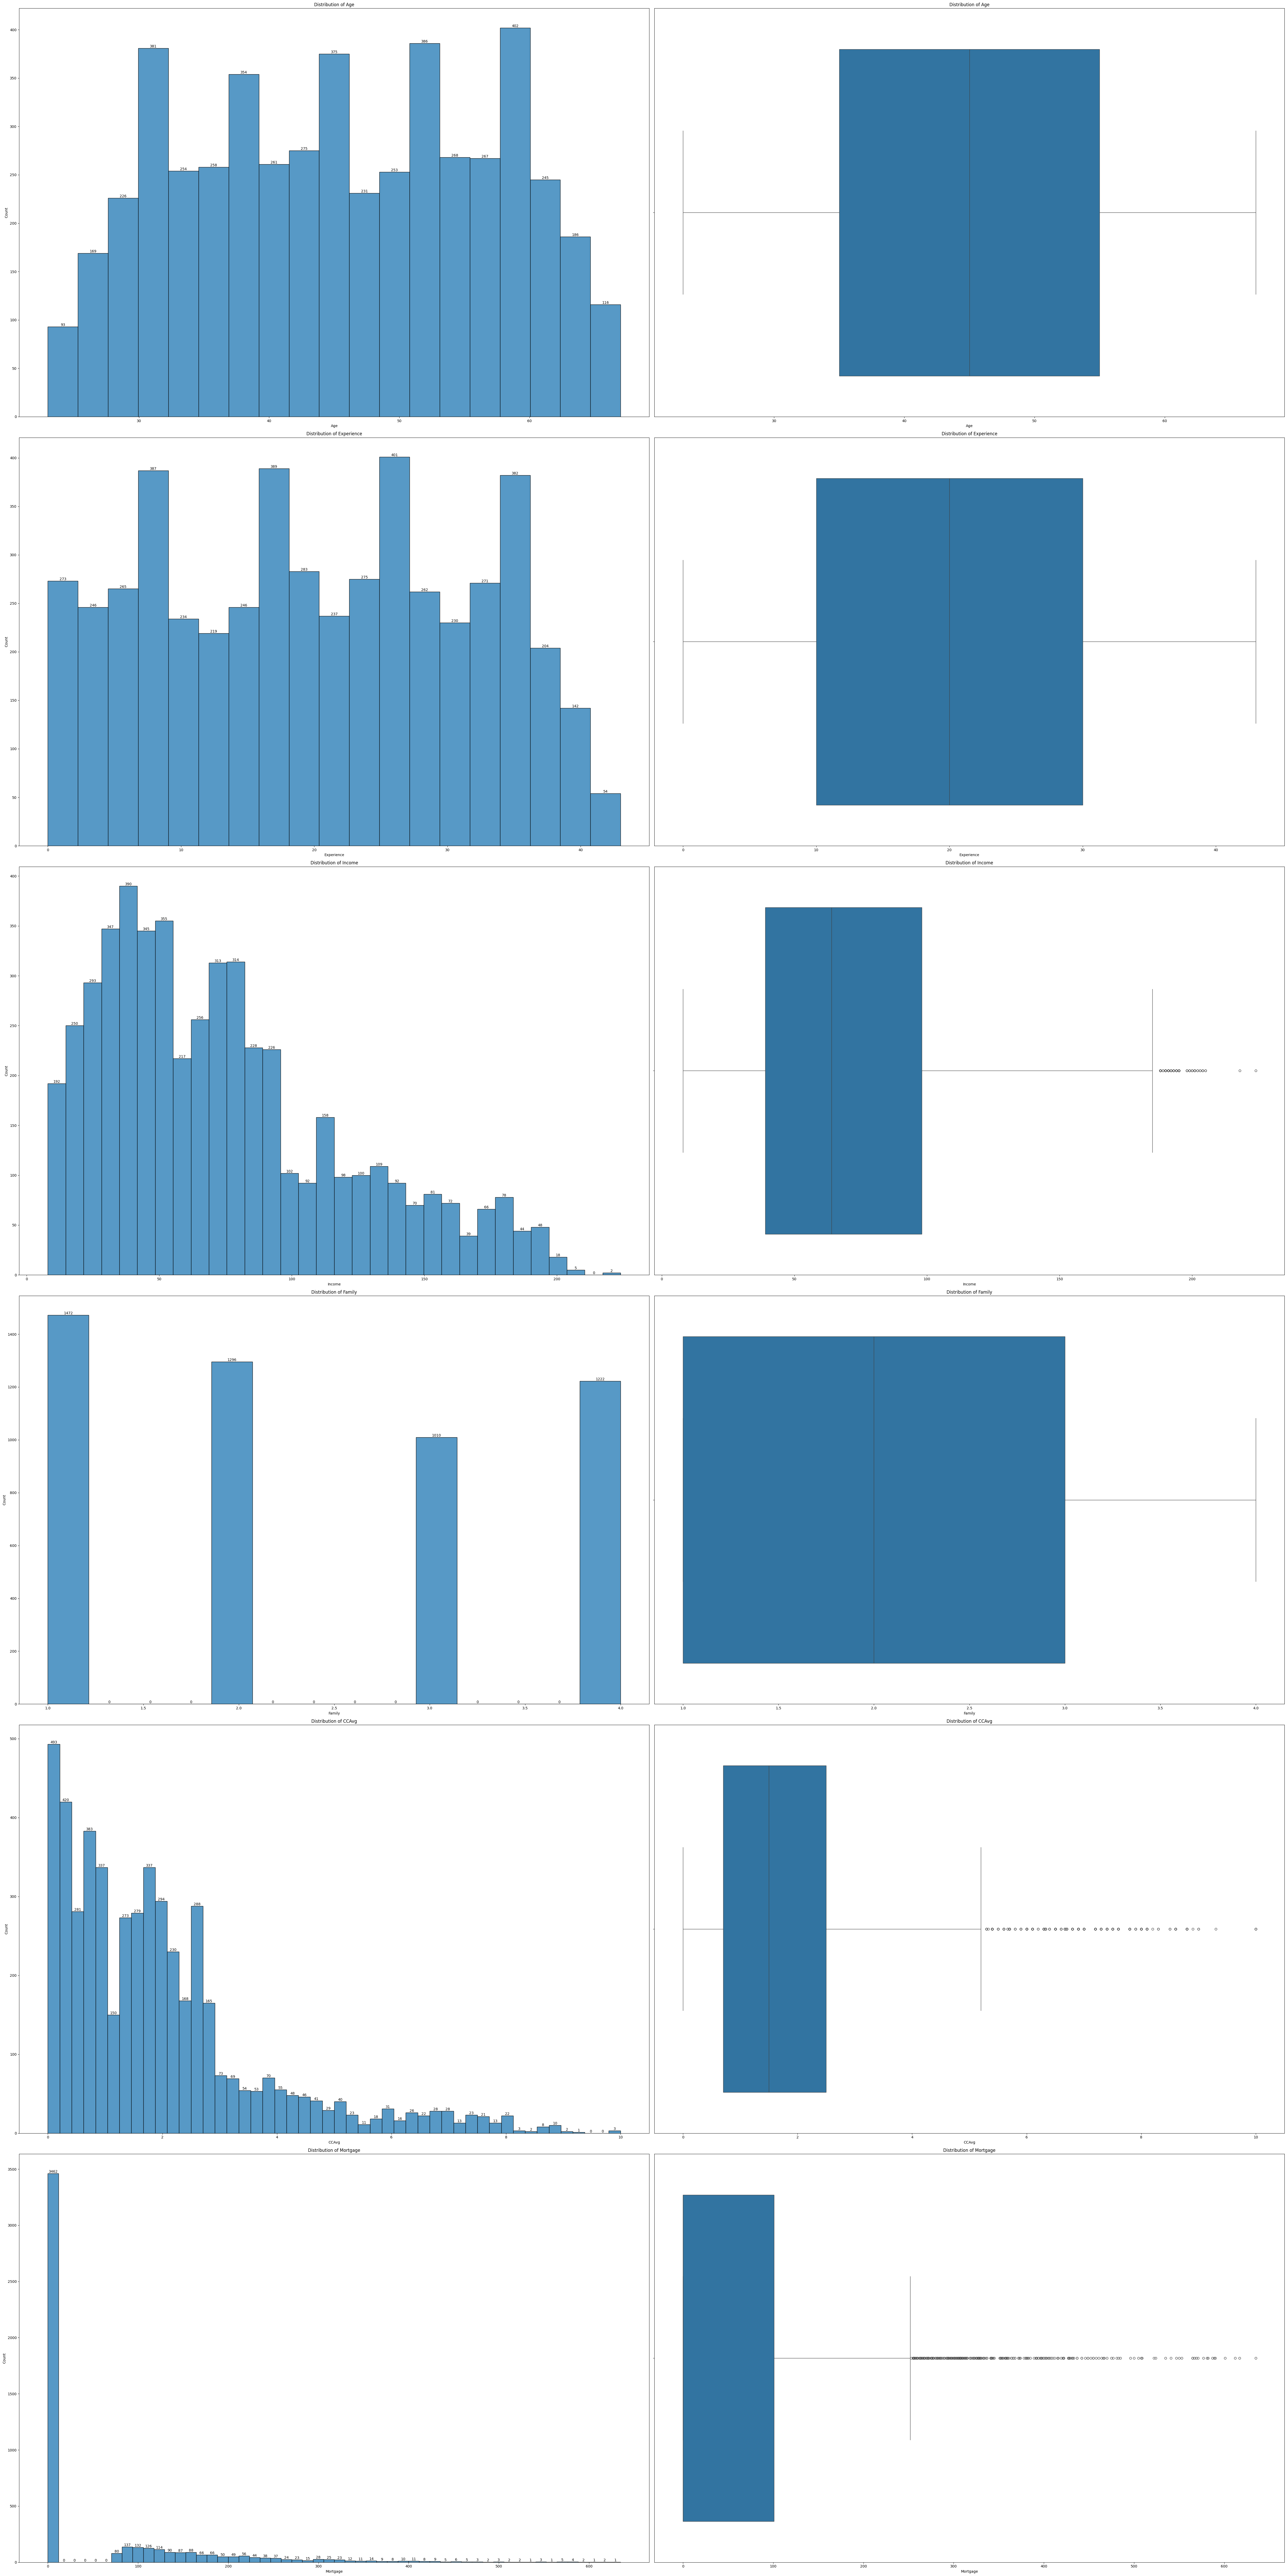

In [ ]:
#plotting histplot and boxplot for numerical columns
numerical_cols = ['Age','Experience','Income','Family','CCAvg','Mortgage']

fig, axes = plt.subplots(6, 2, figsize=(50, 100))

for i, col in enumerate(numerical_cols) :
  sns.histplot(data = data, x = col, ax=axes[i,0])
  axes[i,0].set_title(f'Distribution of {col}')
  axes[i,0].bar_label(axes[i,0].containers[0])

  sns.boxplot(data=data, x=col, ax=axes[i,1])
  axes[i,1].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()



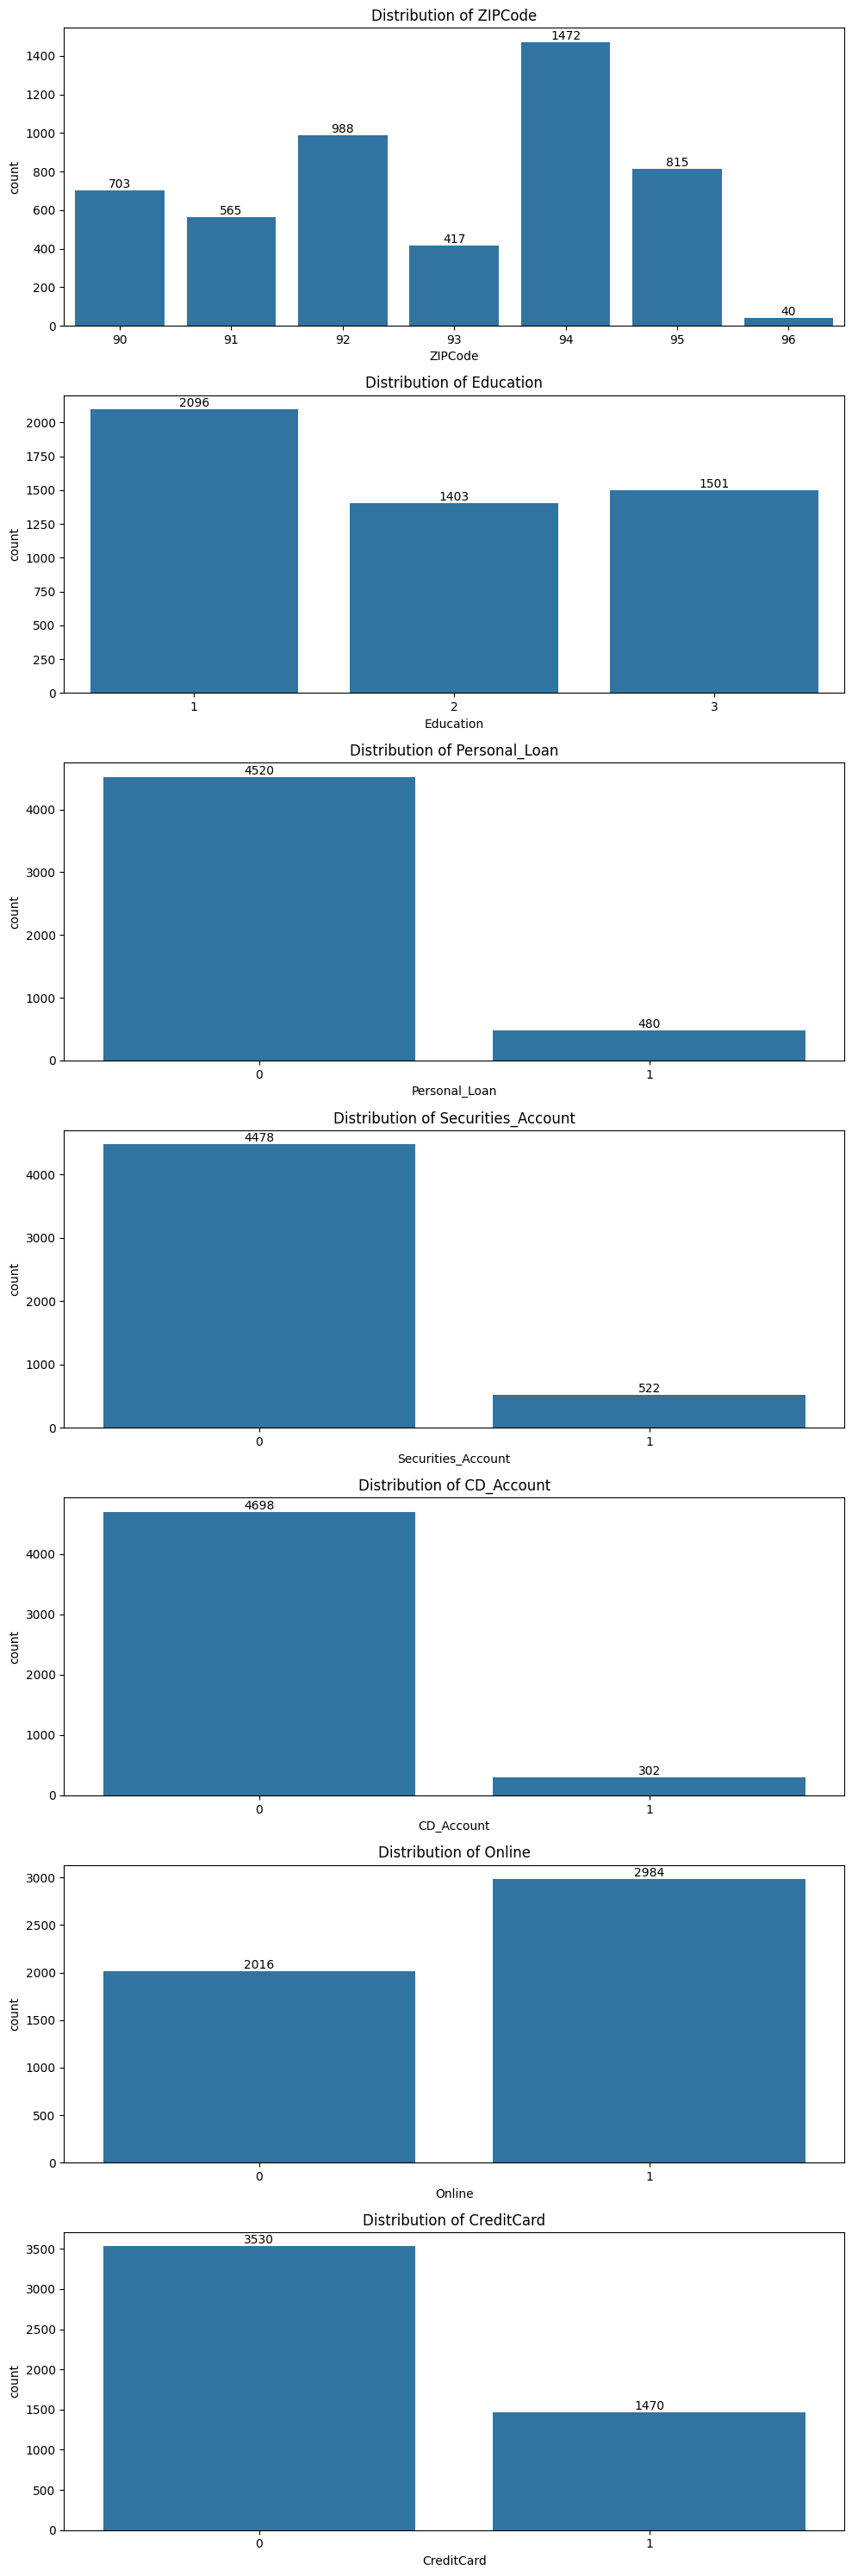

In [ ]:
#plotting countplot for categorical columns
categorical_cols = ['ZIPCode','Education','Personal_Loan','Securities_Account','CD_Account','Online','CreditCard']
len_cat_cols = len(categorical_cols)

fig, axes = plt.subplots(len_cat_cols, 1, figsize=(10,30))

for i, col in enumerate(categorical_cols) :
  sns.countplot(data = data, x = col, ax=axes[i])
  axes[i].set_title(f'Distribution of {col}')
  axes[i].bar_label(axes[i].containers[0])
plt.tight_layout()
plt.show()

### **OBSERVATIONS**:
Questions:
- What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
- How many customers have credit cards?

Univariant Analysis Answers:
- Mortgage distribution is heavily right skewed since there are 3462 out of 5000 customers with no mortgage. Hence it affects the mean and outliers too for box plot
- 1470 customers have credit cards.

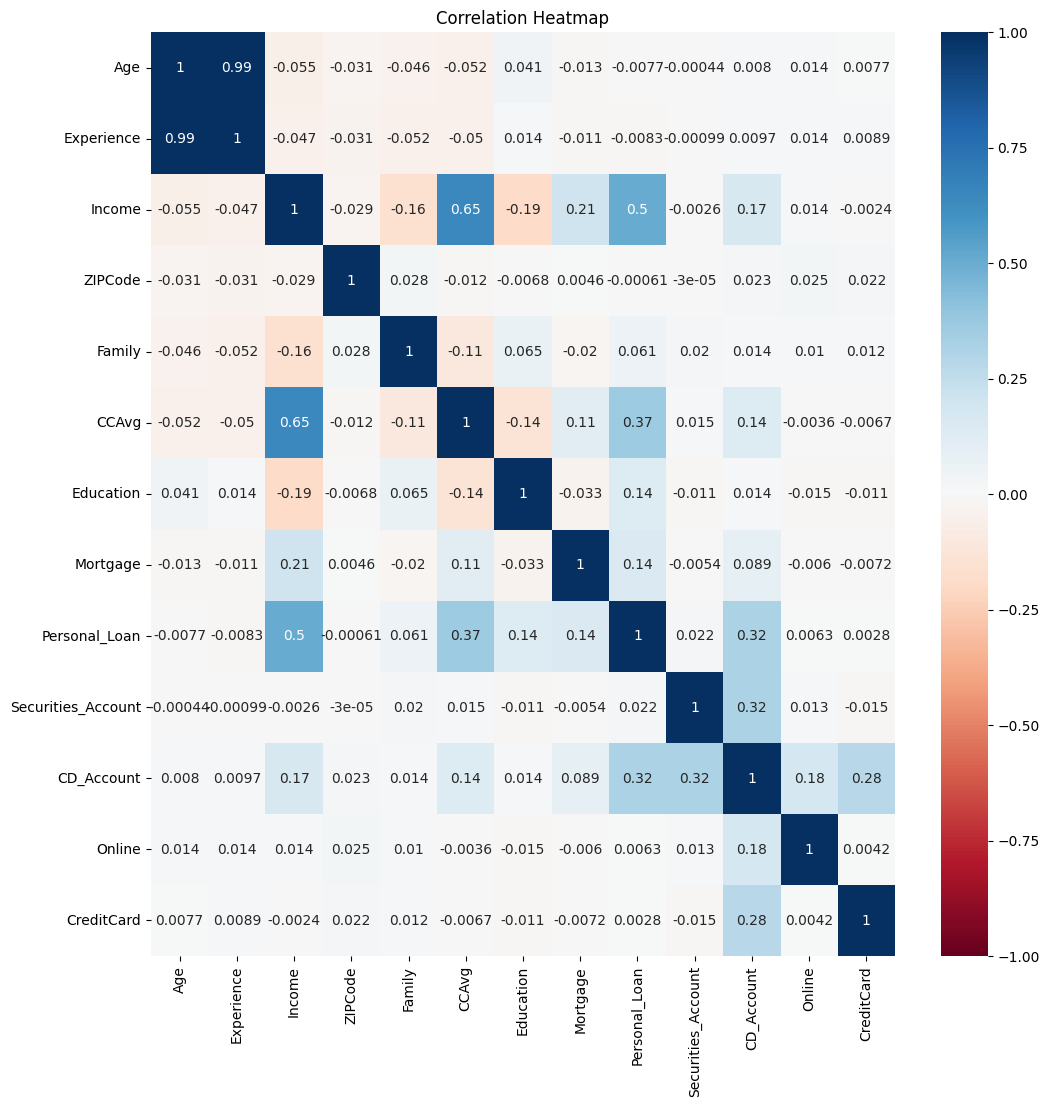

In [ ]:
plt.figure(figsize=(12, 12))
sns.heatmap(data.corr(), annot=True, cmap="RdBu", vmax=1, vmin=-1)
plt.title("Correlation Heatmap")
plt.show()

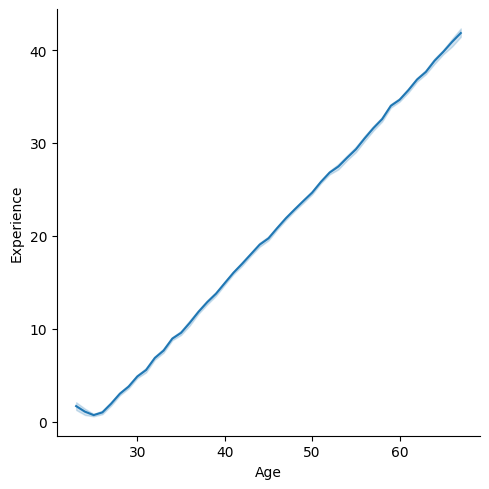

In [ ]:
sns.relplot(data=data,x='Age',y='Experience',kind='line')
plt.show()

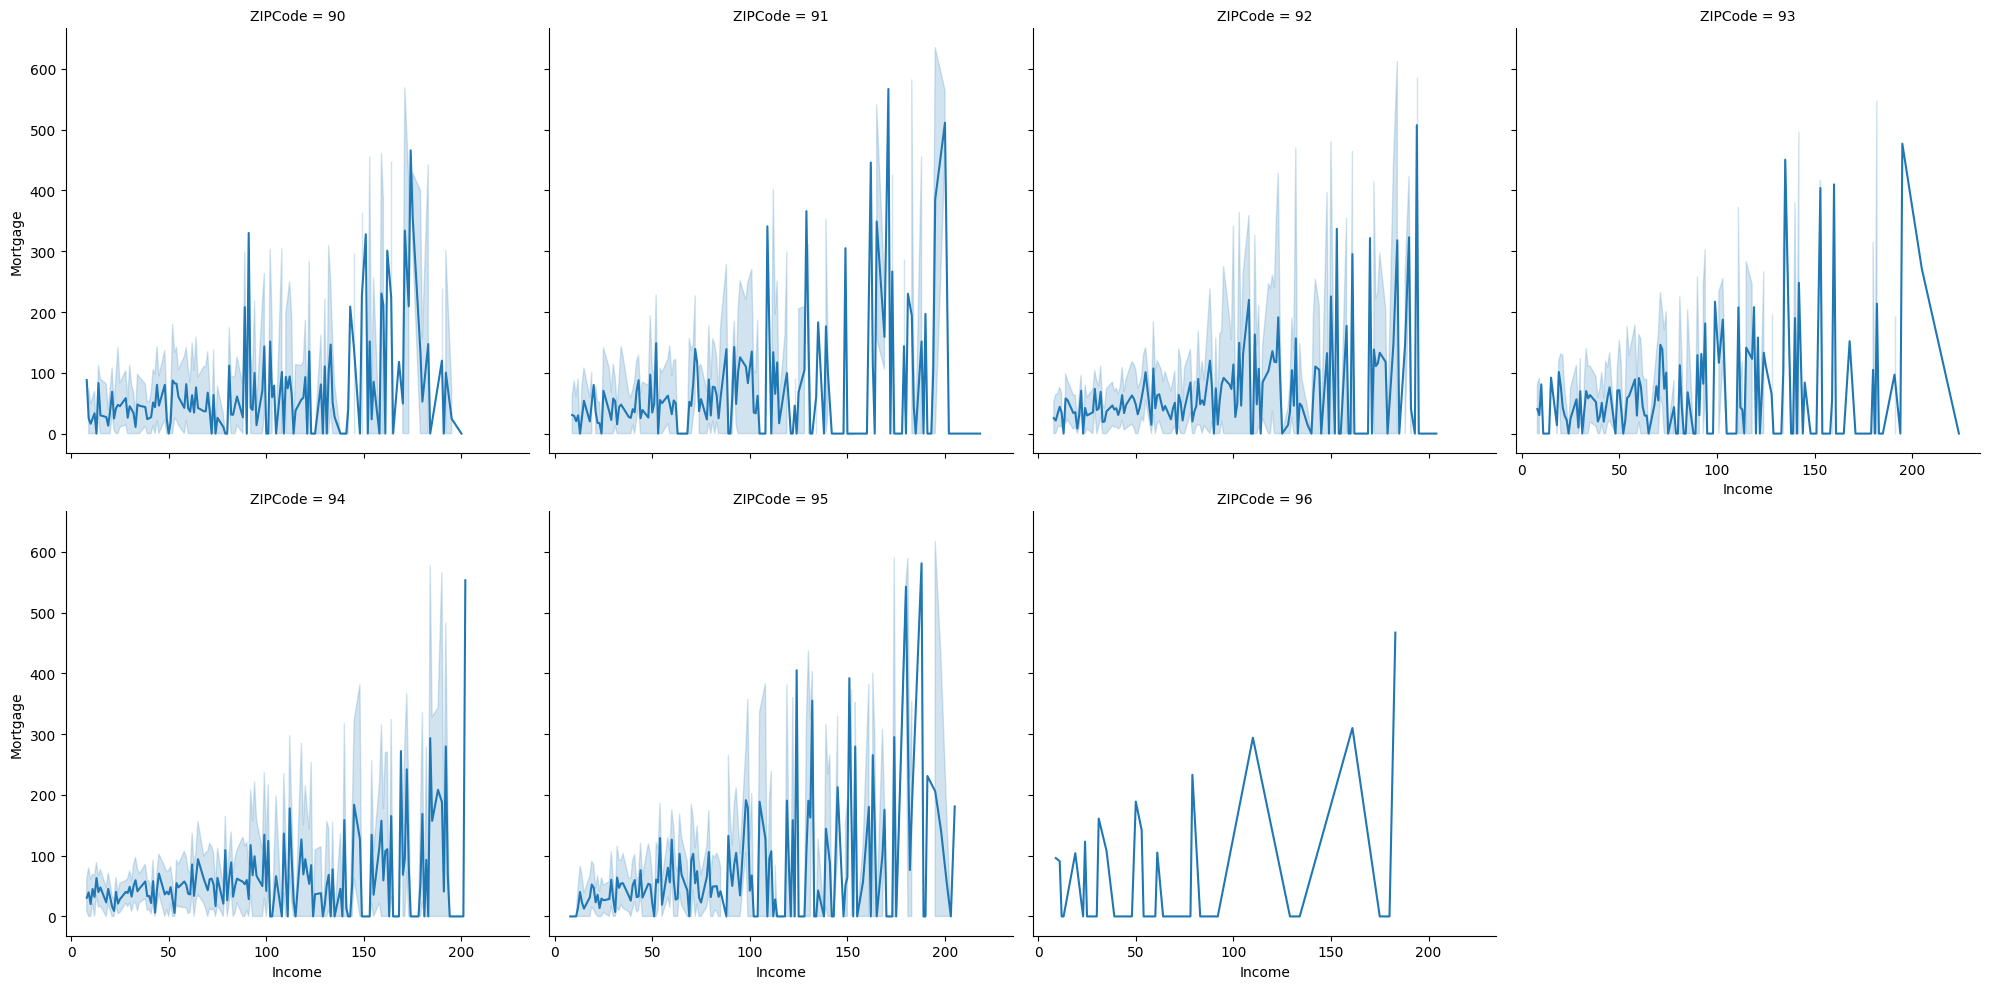

In [ ]:
sns.relplot(data=data,x='Income',y='Mortgage',col='ZIPCode',kind='line', col_wrap=4)
plt.show()

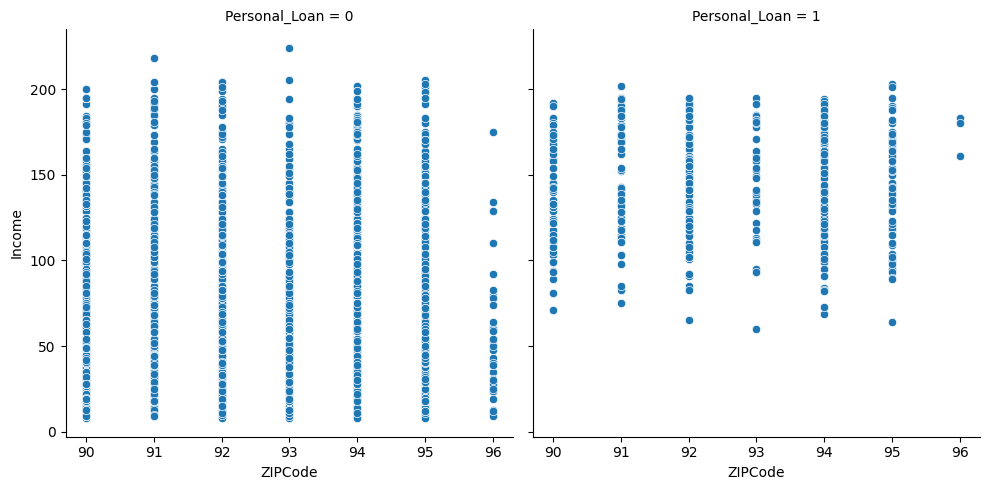

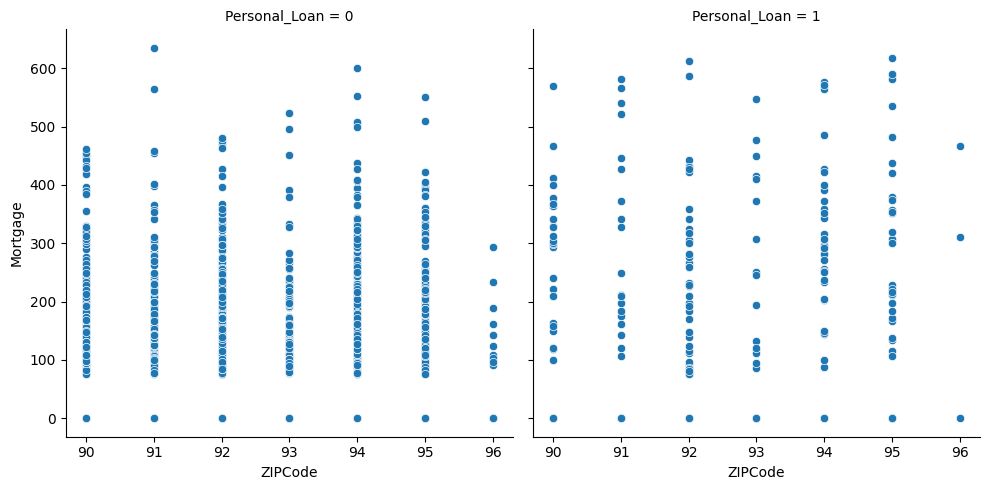

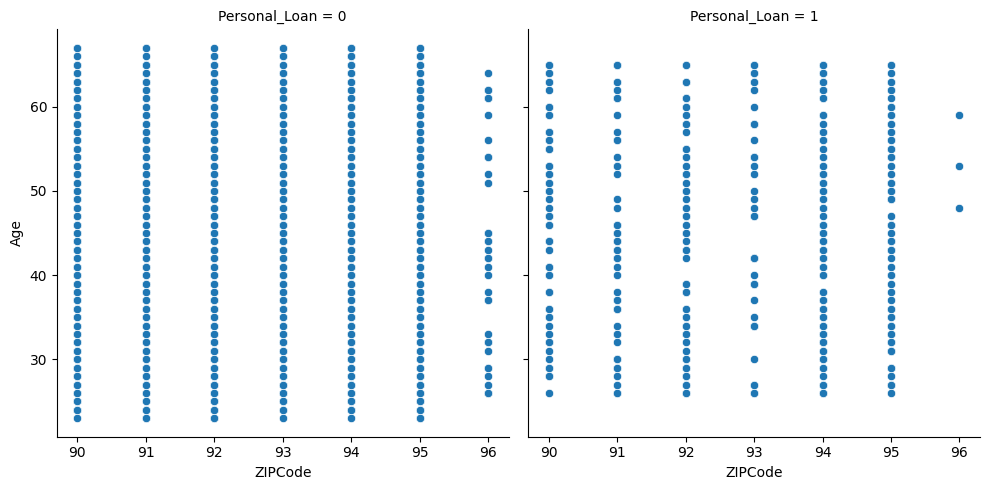

In [ ]:
sns.relplot(data=data,x='ZIPCode',y='Income',col='Personal_Loan',kind='scatter', col_wrap=2)
plt.show()

sns.relplot(data=data,x='ZIPCode',y='Mortgage',col='Personal_Loan',kind='scatter', col_wrap=2)
plt.show()

sns.relplot(data=data,x='ZIPCode',y='Age',col='Personal_Loan',kind='scatter', col_wrap=2)
plt.show()

**OBSERVATIONS:**
- Customers who take Personal Loans have Income > $50000

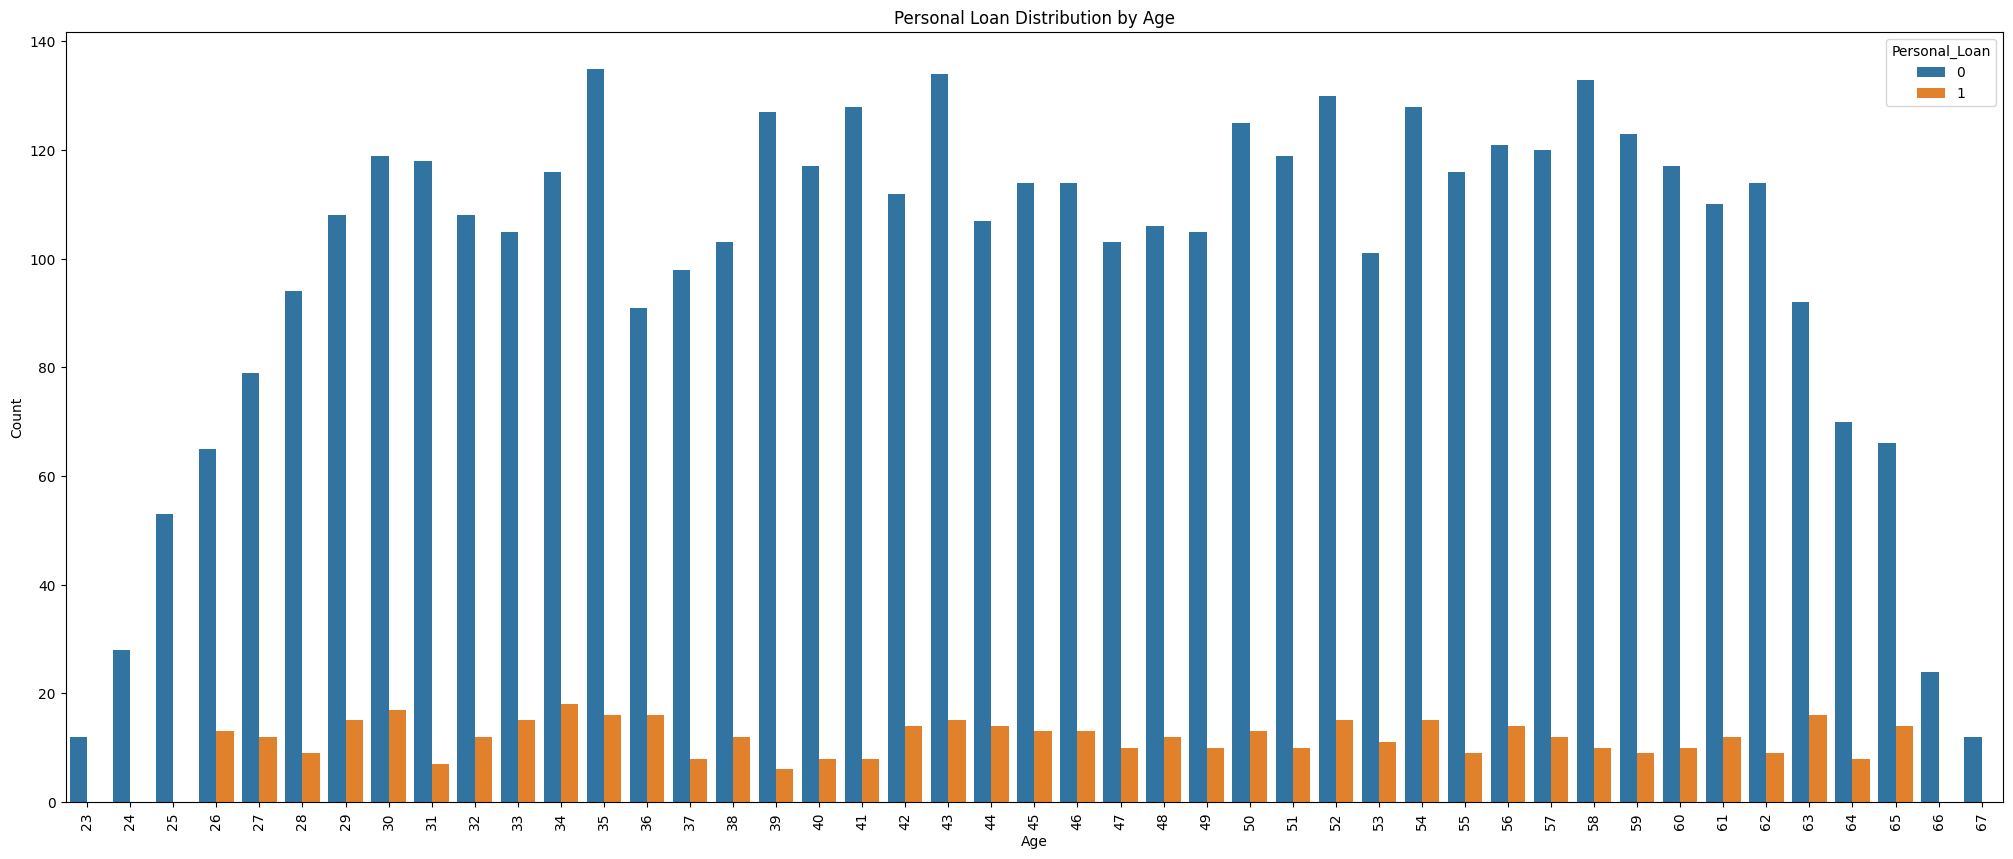

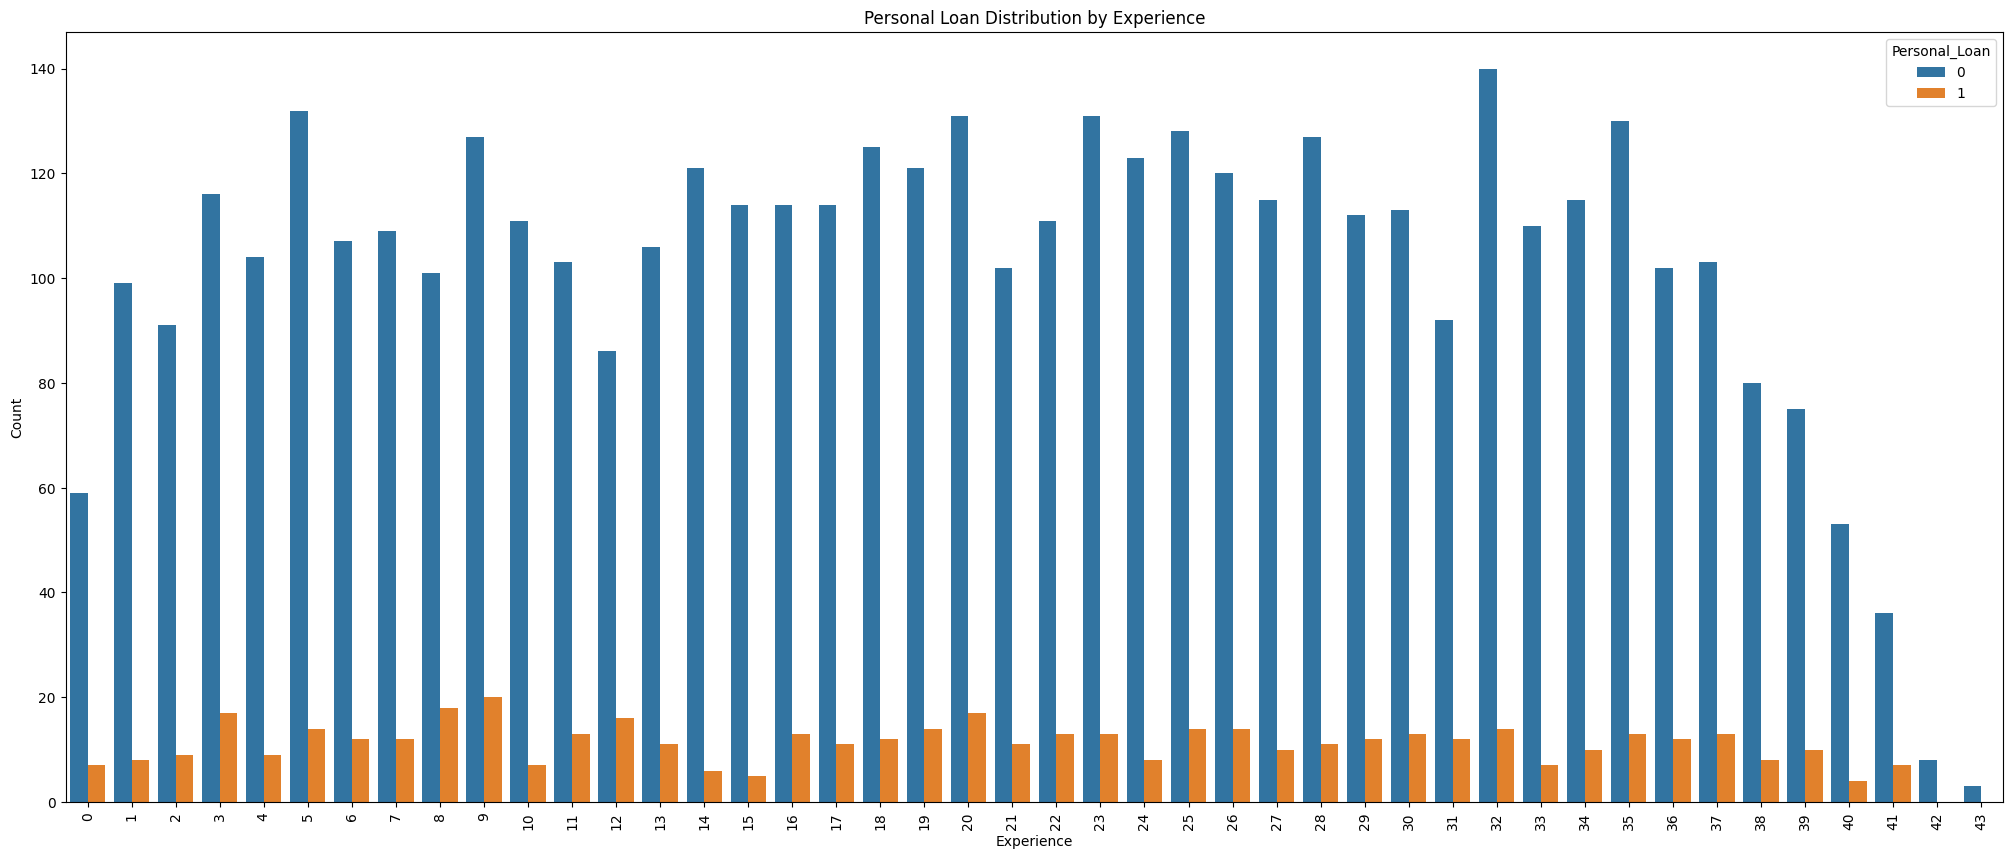

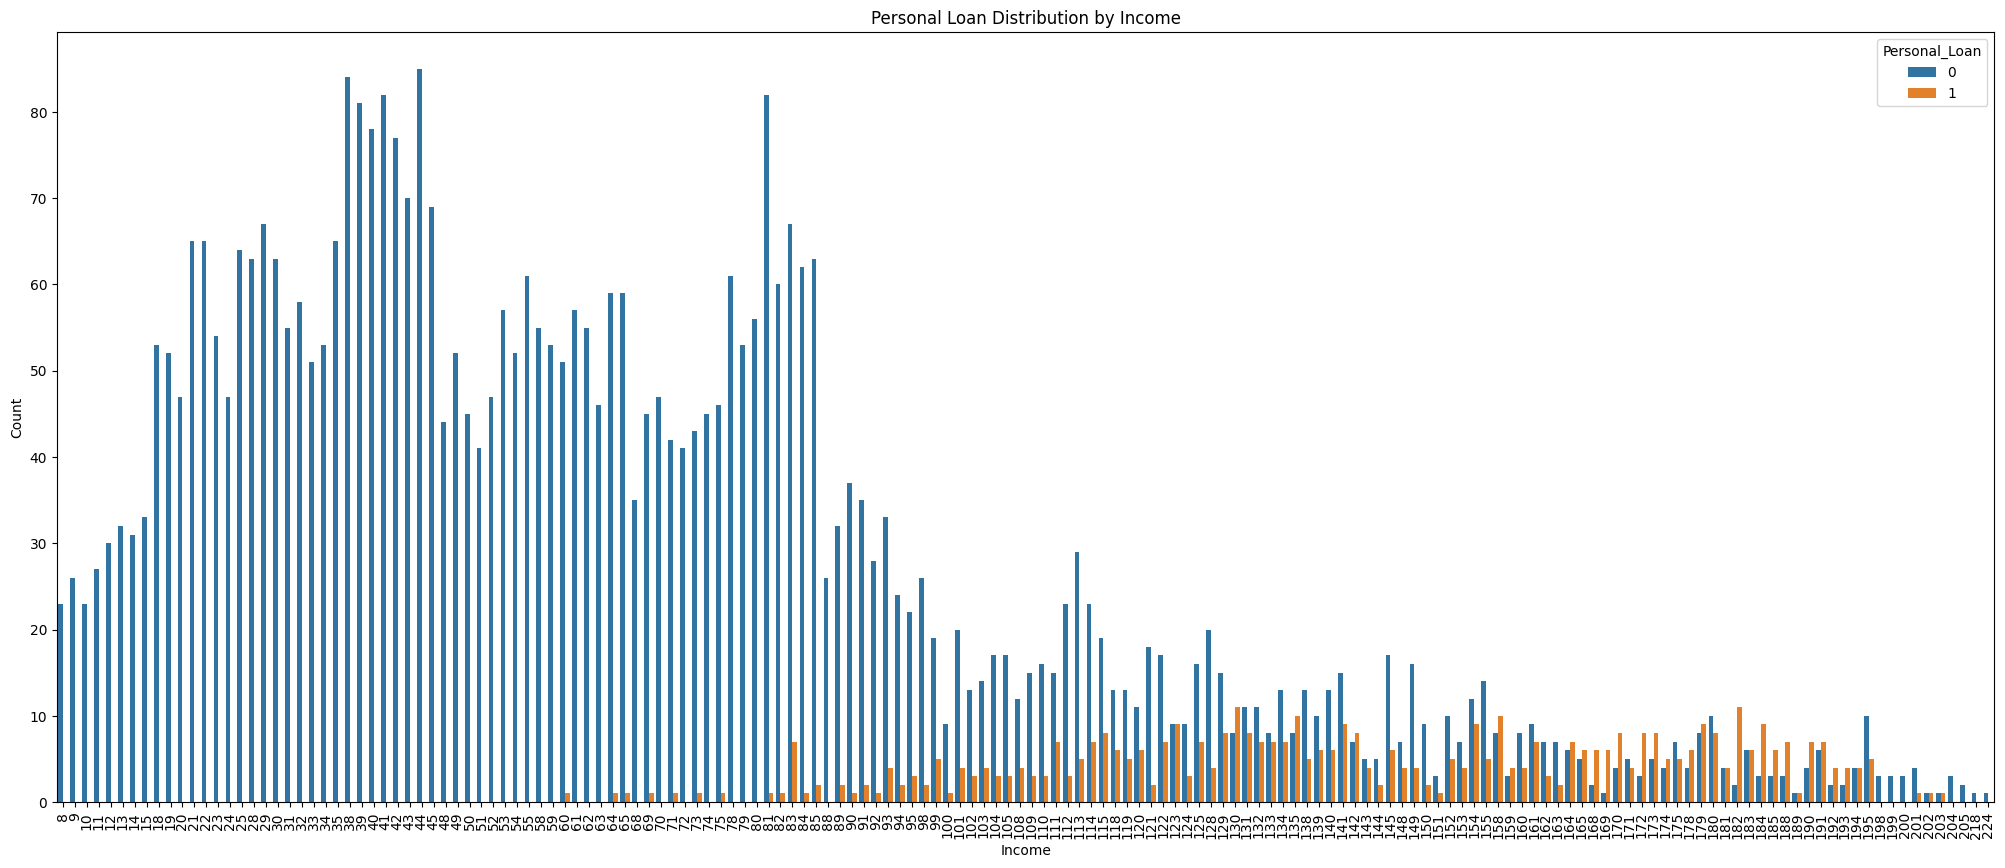

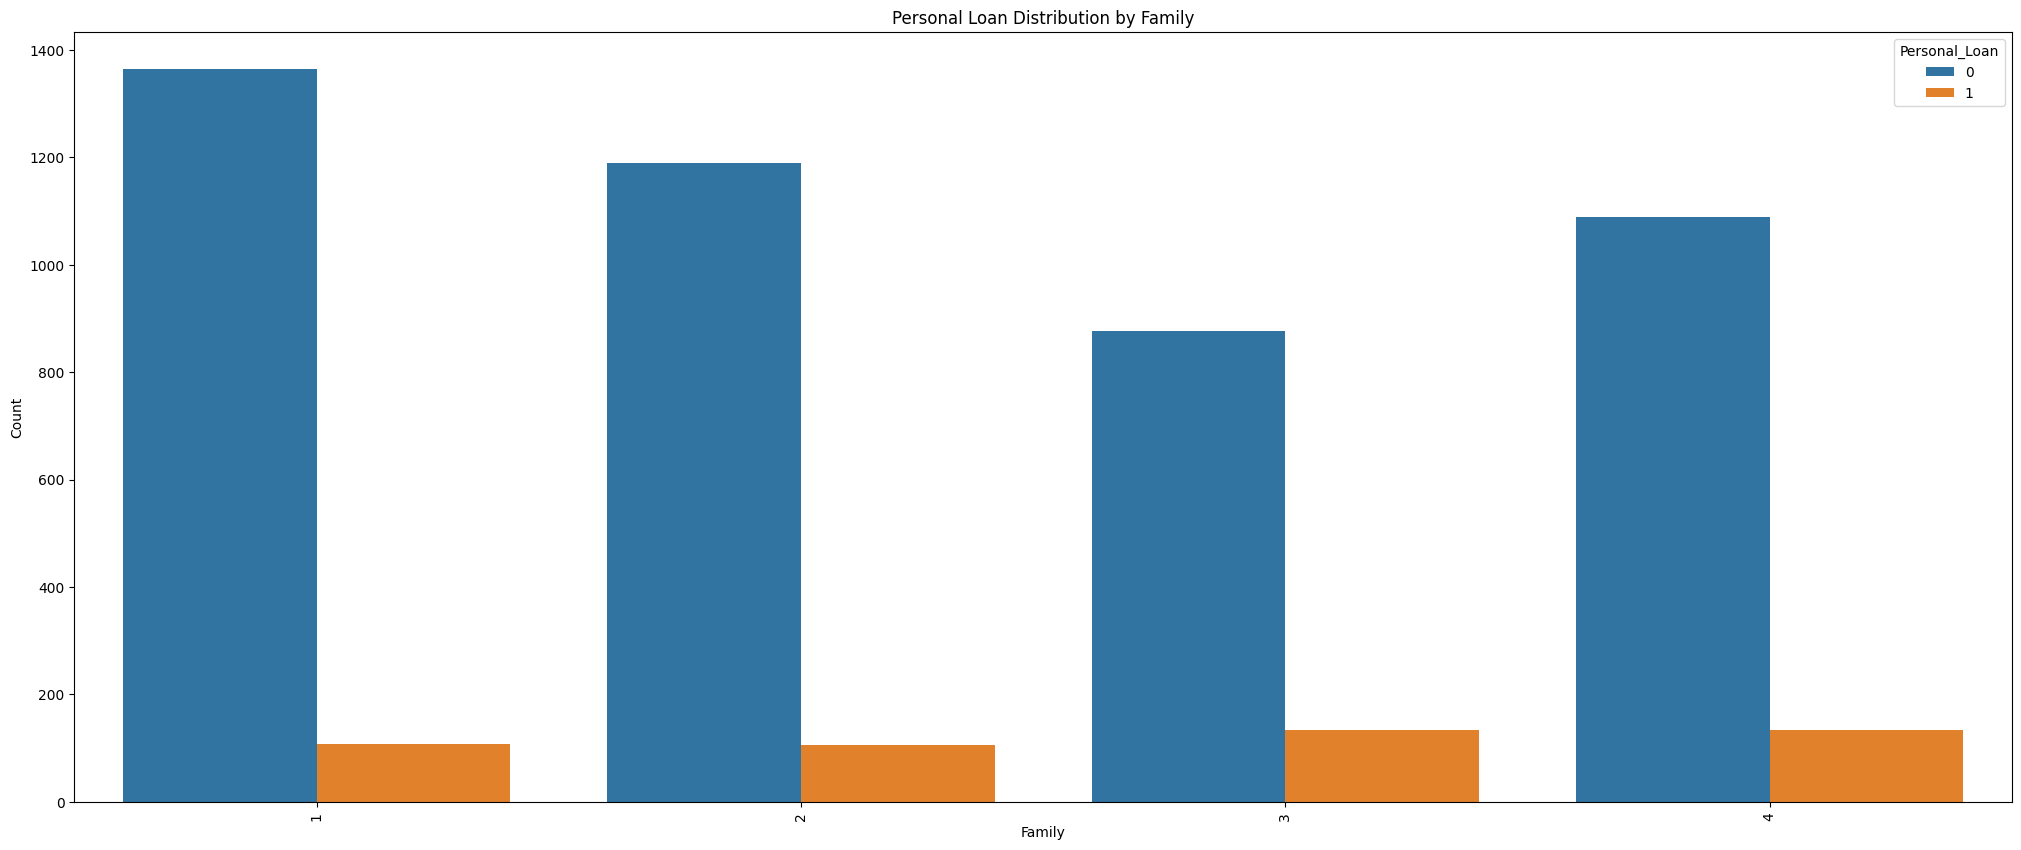

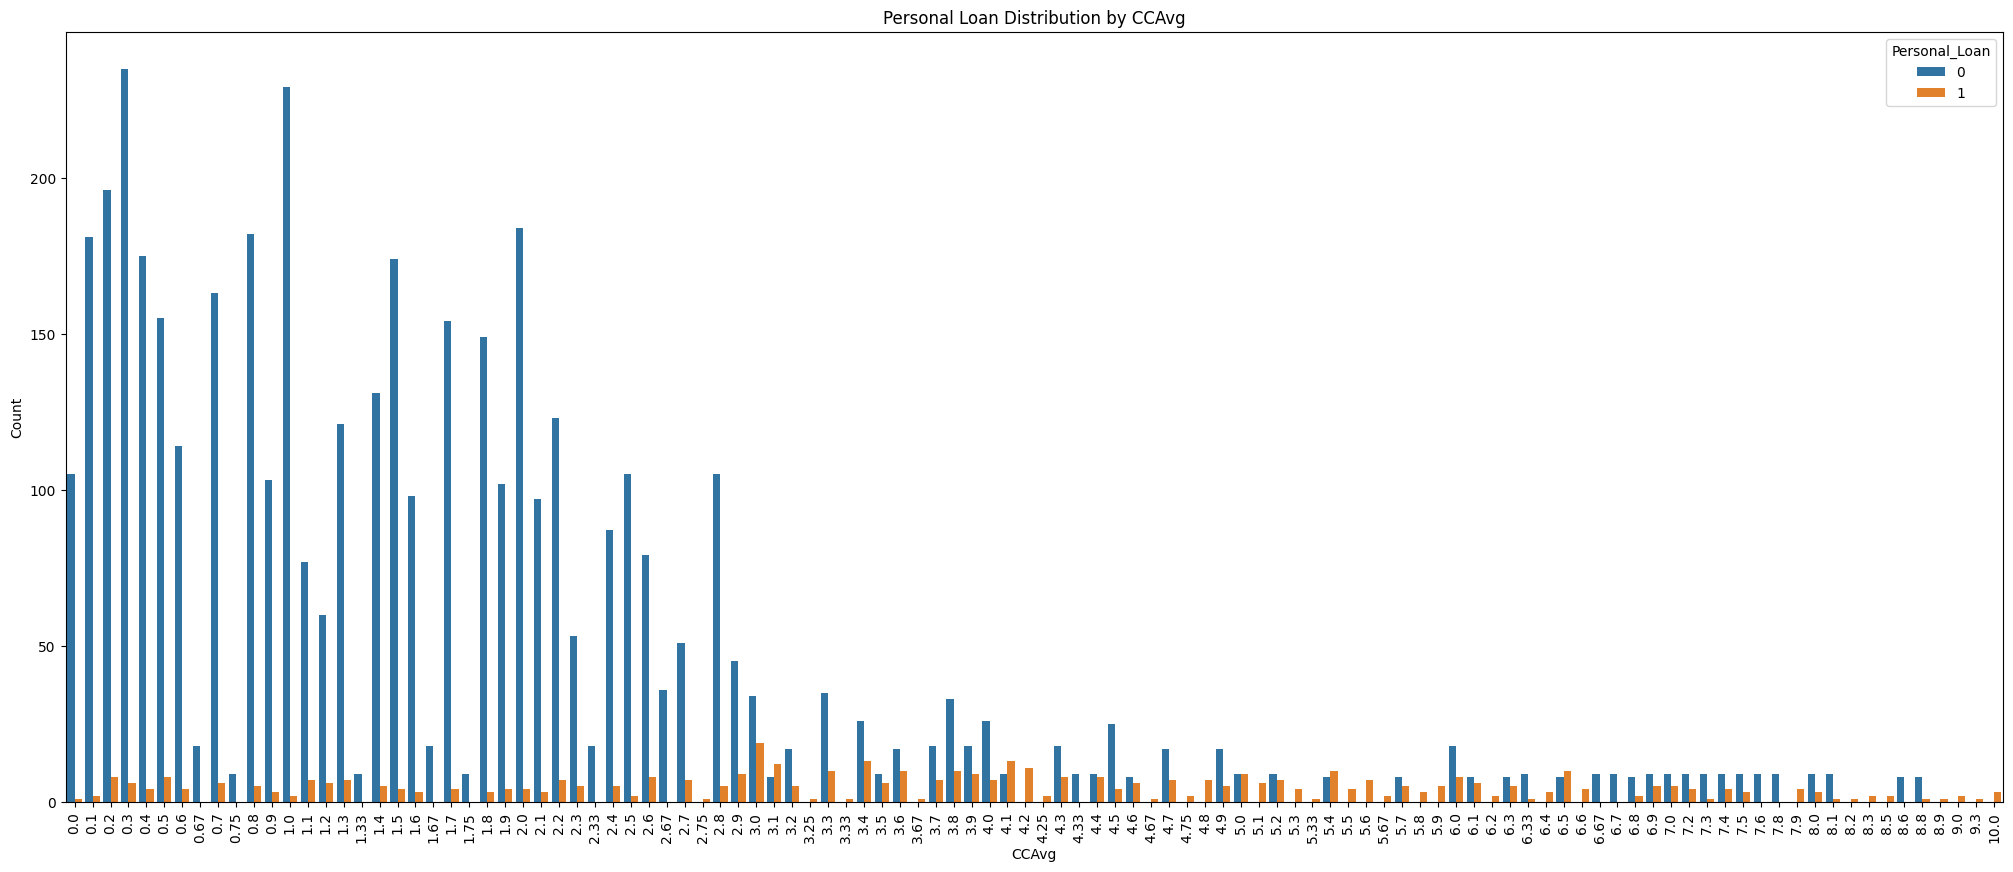

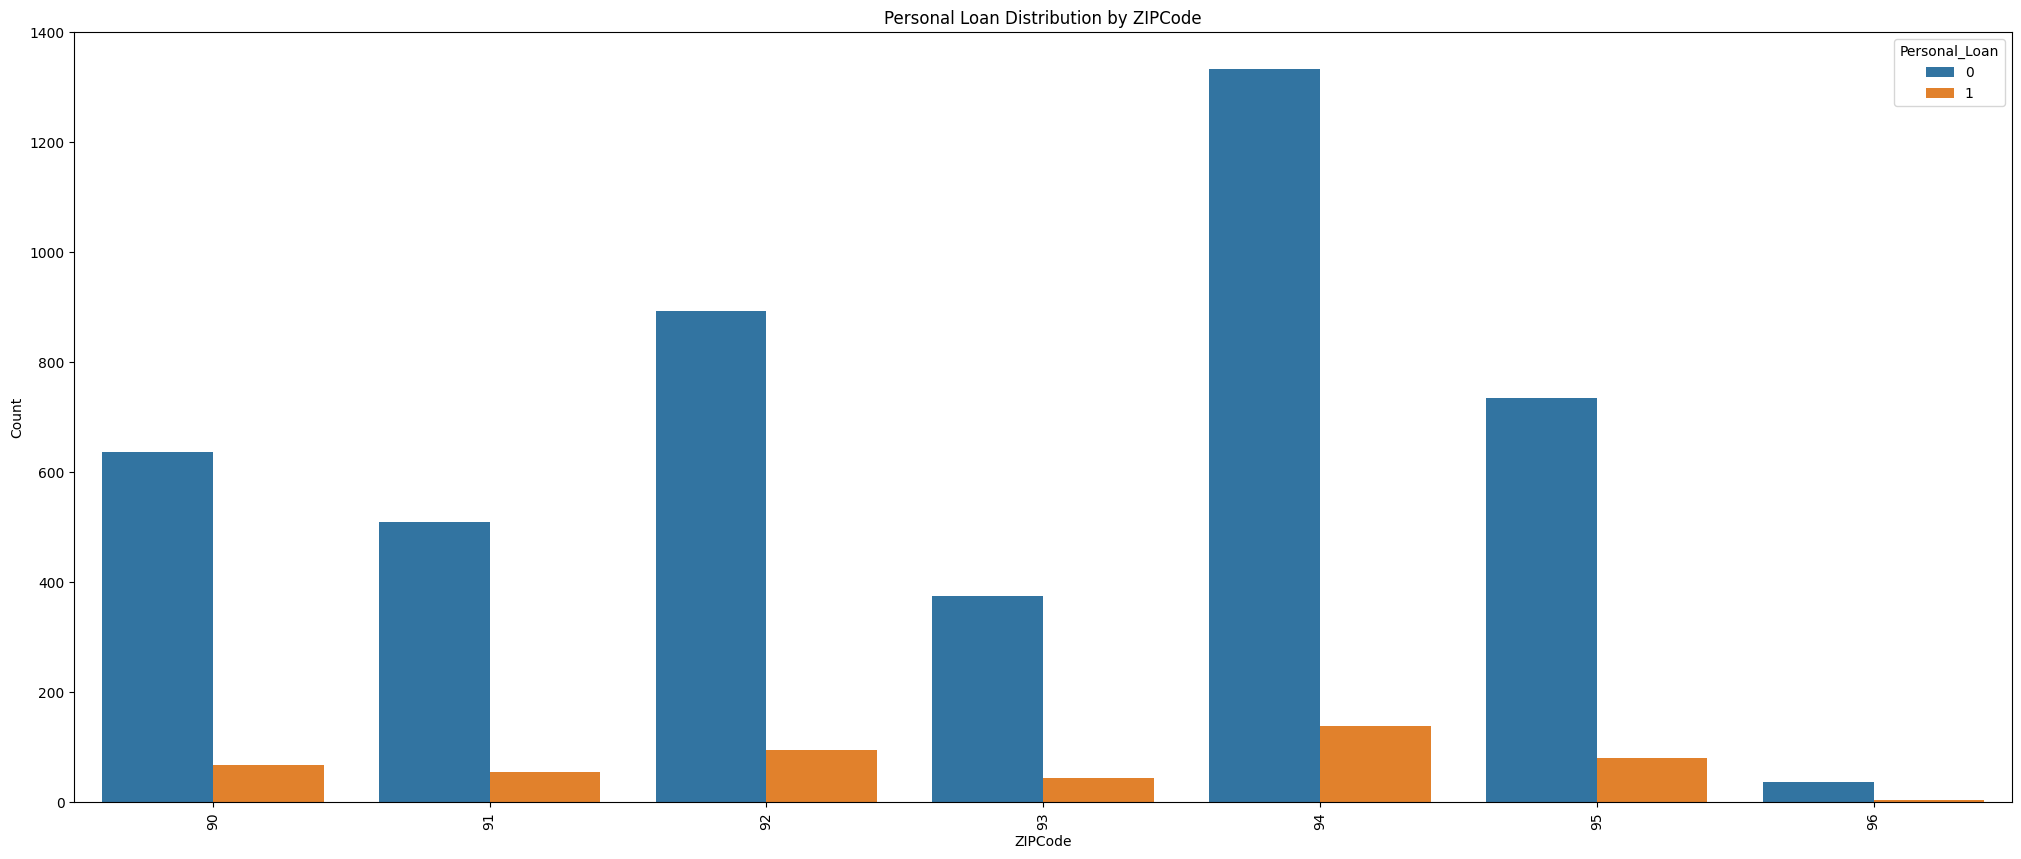

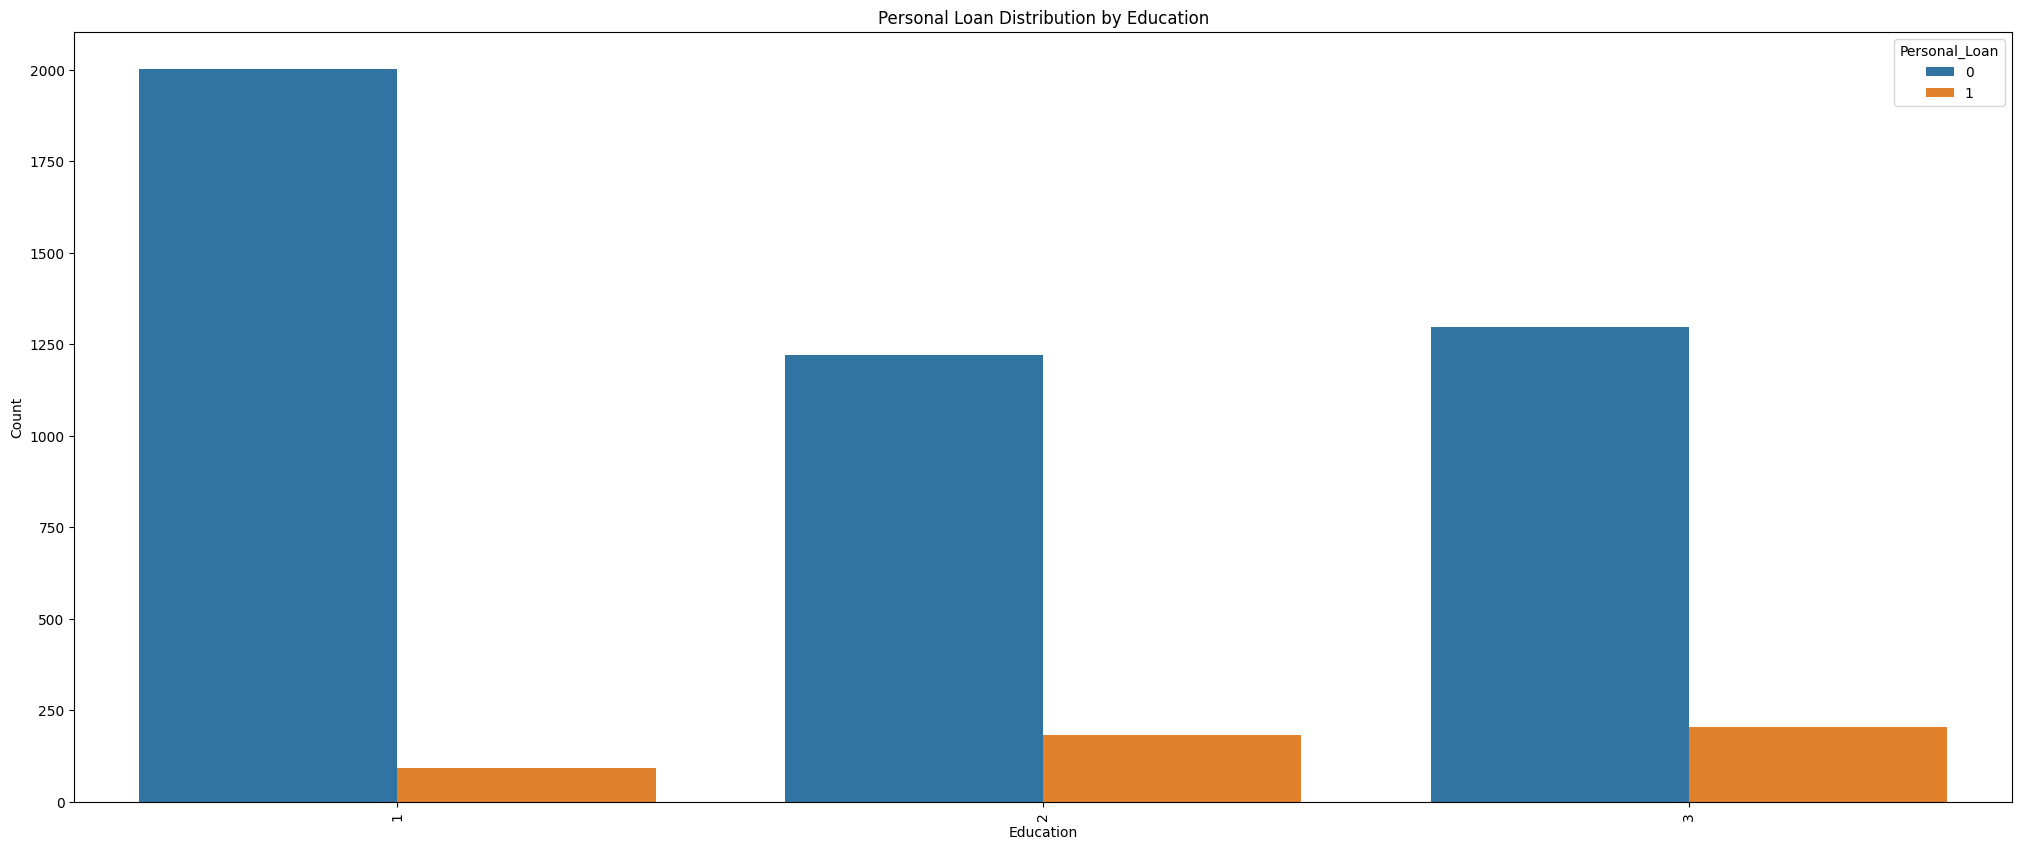

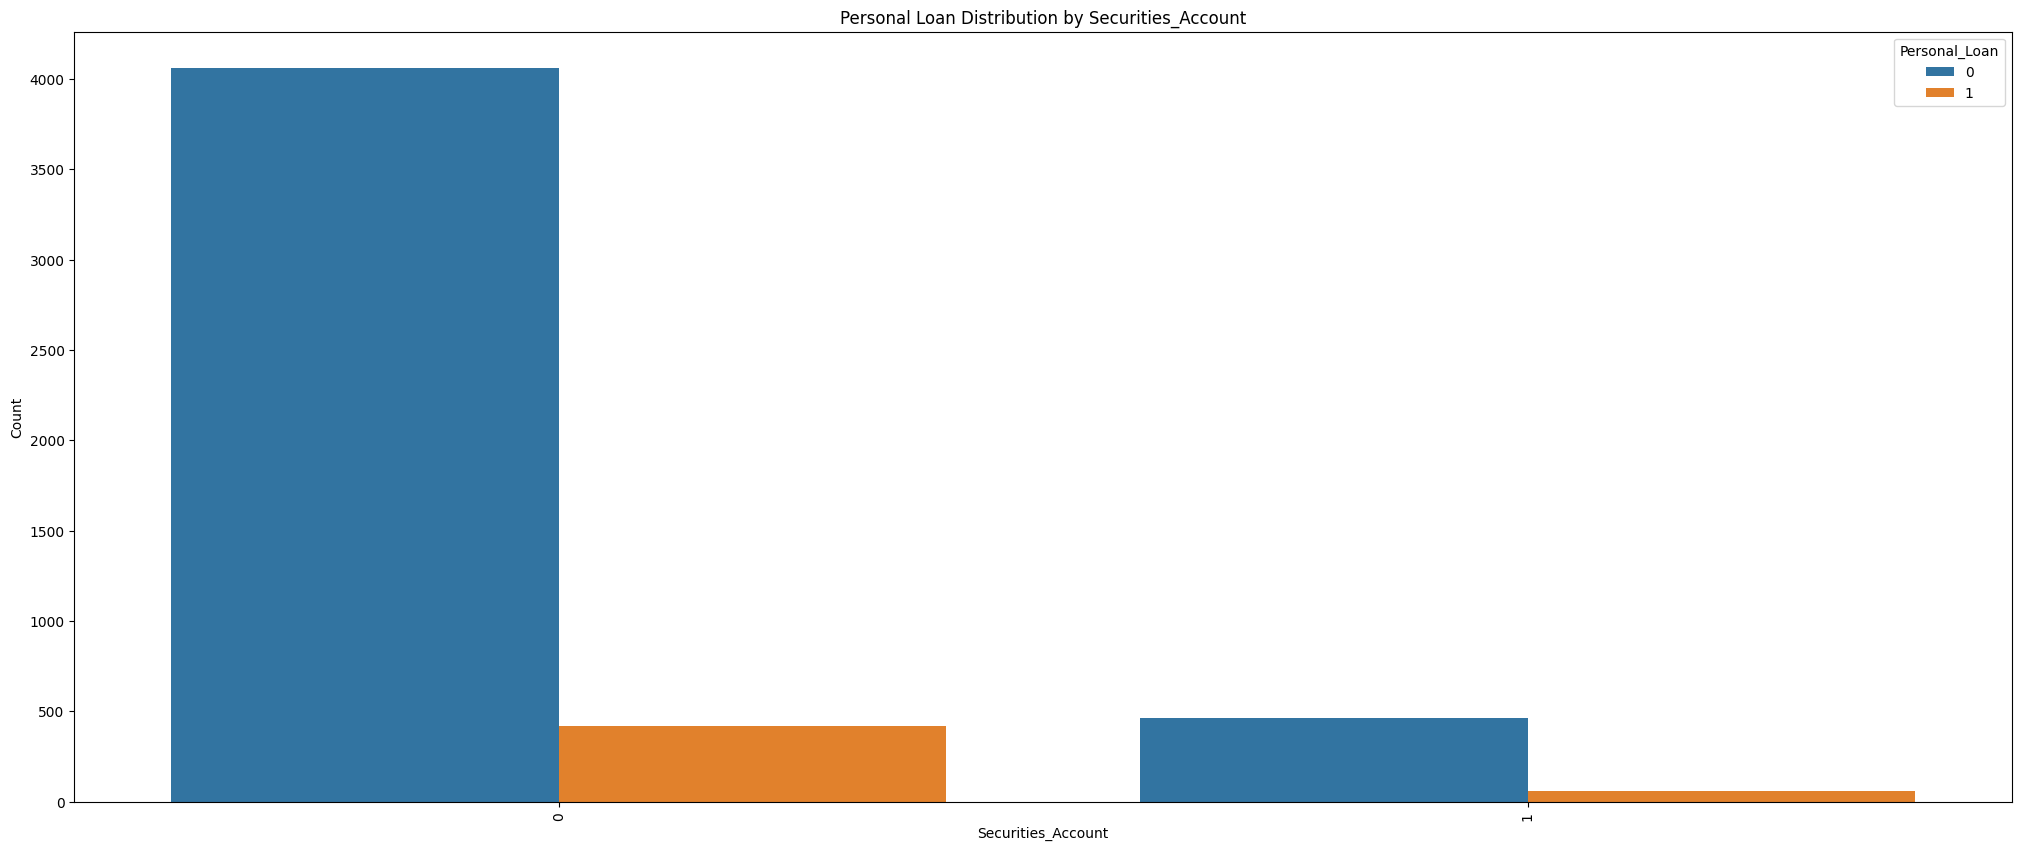

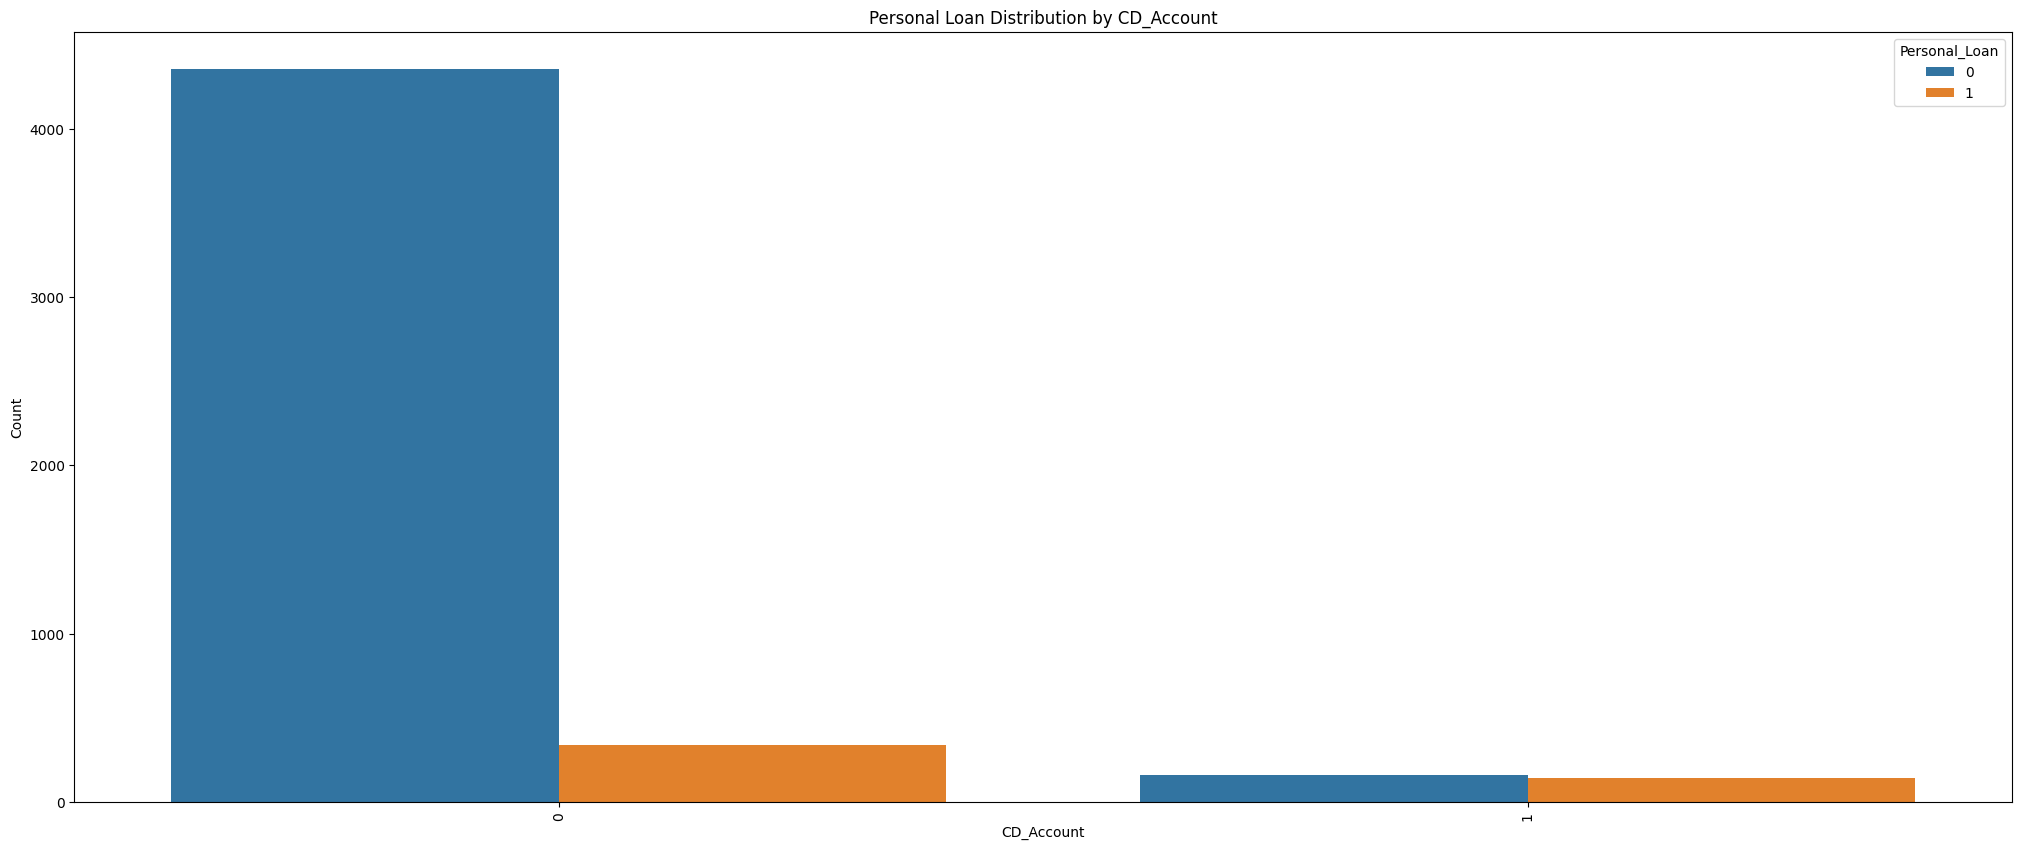

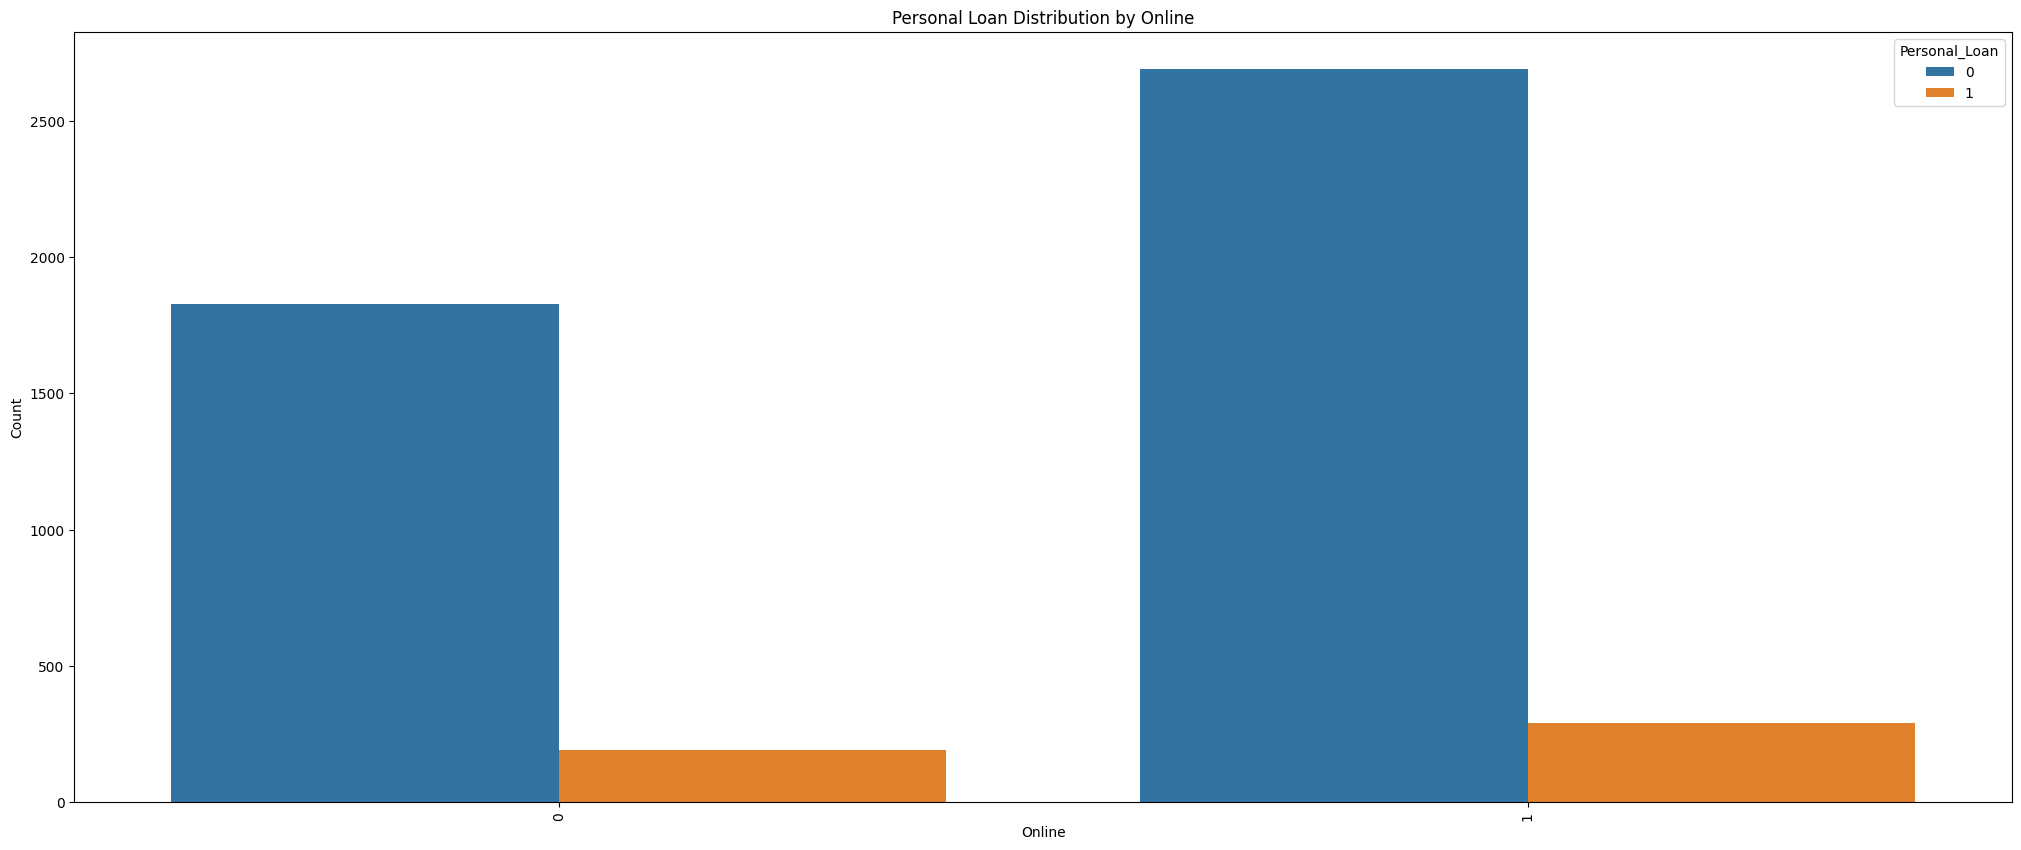

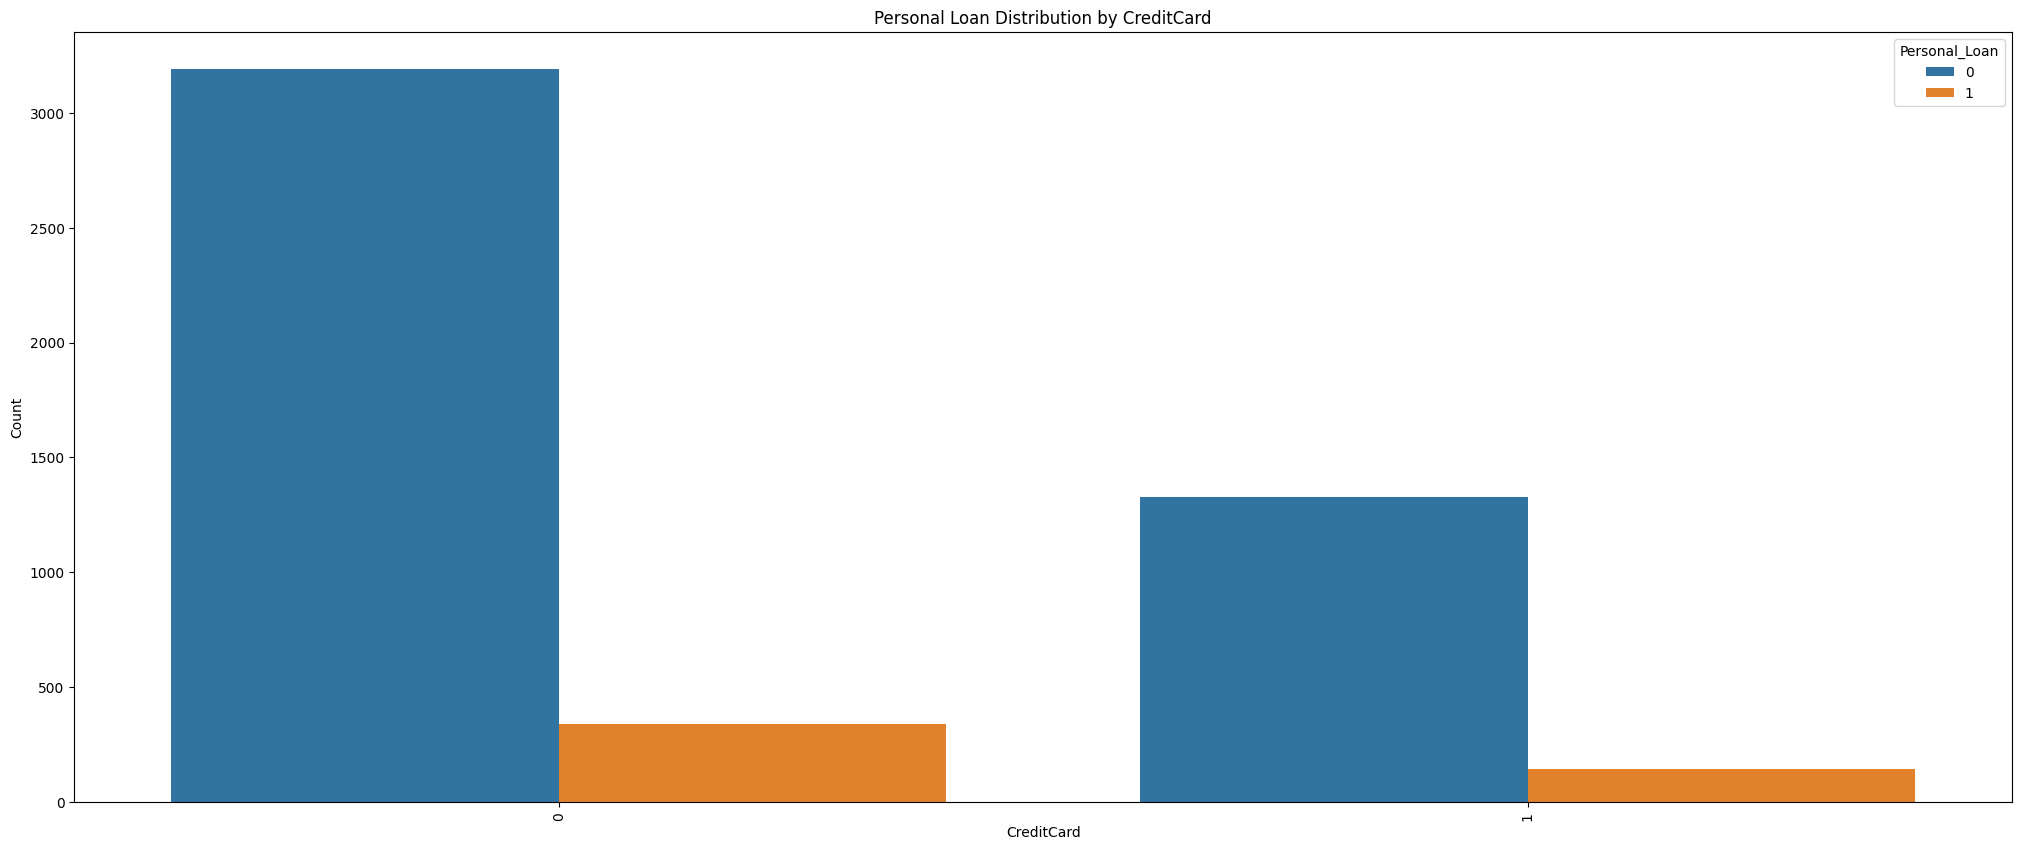

In [ ]:
all_cols = ['Age','Experience','Income','Family','CCAvg','ZIPCode','Education','Securities_Account','CD_Account','Online','CreditCard']
for col in all_cols:
  plt.figure(figsize=(25, 10))
  sns.countplot(data=data, x=col, hue="Personal_Loan")
  plt.xlabel(col)
  plt.ylabel("Count")
  plt.title(f"Personal Loan Distribution by {col}")
  plt.xticks(rotation=90)
  plt.show()

**OBSERVATIONS**:

Questions:
- What are the attributes that have a strong correlation with the target attribute (personal loan)?
- How does a customer's interest in purchasing a loan vary with their age?
- How does a customer's interest in purchasing a loan vary with their education?

**Bivariant analysis observations and answers:**
- Based on the heatmap, *Personal Loan* has a strong correlation with 3 attributes:
  - *Income* (0.5)
  - *CCAvg* (0.37)
  - *CD_Account* (0.32)
- Based on the count plots with Personal Loan,
  - The customer's interest in *Personal Loan* varies with *Age* as such:
    - Customers between ages 26-65 opt for loans. The distribution varies a bit but is not skewed
  - The customer's interest in *Personal Loan* varies with *Education* as such:
    - Customers with higher level of education request more loans.



## Data Preprocessing

* Missing value treatment
  - Not needed.  
* Feature engineering (if needed)
  - ZIPCode is encoded before
  - One hot encoding done below by getdummies
* Outlier detection and treatment (if needed)
  - Outlier detection done below but based on that, no treatment required.
* Preparing data for modeling
  - Drop the target/ dependent/ response variable (Personal_Loan) and consider the other columns as explanatory/ independent variables
* Any other preprocessing steps (if needed)
  - Covered in other aspects

### Outlier detection and treatment

In [ ]:
#Calculate outliers for all datatypes of float , int to know if there are any columns with major outliers that can affect the model performance
Q1 = data.select_dtypes(include=["float64", "int64"]).quantile(0.25)
Q3 = data.select_dtypes(include=["float64", "int64"]).quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [ ]:
# Outlier percents for all data types of float, int
((data.select_dtypes(include=["float64", "int64"]) < lower) | (data.select_dtypes(include=["float64", "int64"]) > upper)).sum() / len(data) * 100

,0
Age,0.00
Experience,0.00
Income,1.92
Family,0.00
CCAvg,6.48
Mortgage,5.82


### Preparing Data for modeling and feature engineering
  - *Personal_Loan* is our target variable so that will be Y. So we drop it from X
  - We can also drop attributes which have no correlation to *Personal_Loan*
  (i.e. from the heatmap, the attributes with which the *Personal_Loan* correlation is close to 0)
  - *Age*, *Experience*, *ZIPCode*, *Online* and *Credit_Card* have weak correlations with *Personal_Loan*
  - To not oversimplify the model, let's drop *Experience* only for now as it is perfectly correlated to *Age* (based on the relplot above), so having one of the 2 attributes in the model is fine

In [ ]:
X = data.drop(["Personal_Loan", "Experience"], axis=1)
Y = data["Personal_Loan"]

X = pd.get_dummies(X, columns=["ZIPCode", "Education"], drop_first=True)

X = X.astype(float)

# Splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42)

X.head()

,Age,Income,Family,CCAvg,Mortgage,Securities_Account,CD_Account,Online,CreditCard,ZIPCode_91,ZIPCode_92,ZIPCode_93,ZIPCode_94,ZIPCode_95,ZIPCode_96,Education_2,Education_3
0,25.0,49.0,4.0,1.6,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,45.0,34.0,3.0,1.5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,39.0,11.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,35.0,100.0,1.0,2.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,35.0,45.0,4.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
print("Training set size: ", X_train.shape)
print("Testing set size: ", X_test.shape)
print("\n")
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("\n")
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Training set size:  (4000, 17)
Testing set size:  (1000, 17)


Percentage of classes in training set:
Personal_Loan
0    0.90625
1    0.09375
Name: proportion, dtype: float64


Percentage of classes in test set:
Personal_Loan
0    0.895
1    0.105
Name: proportion, dtype: float64


## Model Building

### Model Evaluation Criterion


- We will build 2 functions for evaluation of our model. After running the model on training or testing set we will call these functions to evaluate the model performance
  1. compute_model_evaluation_criterion

  - To compute following metrics from sklearn.metrics library:
    - Accuracy: (0.0 - 1.0) - How many correct predictions did the model make (Customers with and without Personal Loan)
    - Recall: (0.0 - 1.0) - Out of All Customers with Personal Loan (True Pos + False neg), how many were correctly predicted to have Personal Loan
    - Precision: (0.0 - 1.0) - Out of All Customers predicted with Personal Loan (True+ False Positives), how many actually have Personal Loan
    - F1 Score: (0.0 - 1.0) - Balancing Recall and Precision

  2. compute_confusion_matrix

   - Plot True vs Predicted values




### Model Building

### Functions for Evaluation criterion computation

In [ ]:
def compute_model_evaluation_criterion(model, predictors, target):
    pred = model.predict(predictors)

    accuracy = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    df_performance = pd.DataFrame({"Accuracy": accuracy, "Recall": recall, "Precision": precision, "F1": f1,},index=[0],)

    return df_performance

In [ ]:
def compute_confusion_matrix(model, predictors, target):
    pred = model.predict(predictors)

    cm = confusion_matrix(target, pred)

    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(5, 3))
    sns.heatmap(cm, annot=labels, fmt="", cmap="plasma")
    plt.ylabel("True value")
    plt.xlabel("Predicted value")

### Base Model Creation (Training data)

In [ ]:
model = DecisionTreeClassifier(criterion="gini", random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

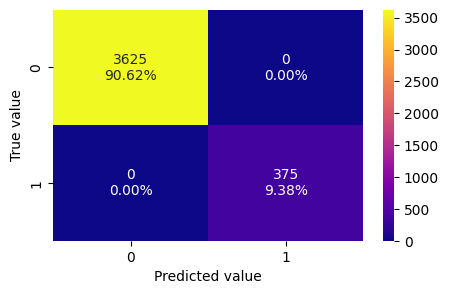

In [ ]:
compute_confusion_matrix(model, X_train, y_train)

**OBSERVATIONS**:

---
- True Meaning:  The customer will have/opt for a Personal Loan
- False Meaning: The customer will not have/ not opt for a Personal Loan
---
- True positive : Predicted True, Actual True: **9.38%**
- True negative : Predicted False, Actual False: **90.62%**
- False positive : Predicted True, Actual False: **0.00%**
- False negative : Predicted False, Actual True: **0.00%**

In [ ]:
decision_tree_perf_train = compute_model_evaluation_criterion(model, X_train, y_train)
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


#### Visualization of Decision Tree

In [ ]:
feature_names = list(X_train.columns)
print(feature_names)

['Age', 'Income', 'Family', 'CCAvg', 'Mortgage', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard', 'ZIPCode_91', 'ZIPCode_92', 'ZIPCode_93', 'ZIPCode_94', 'ZIPCode_95', 'ZIPCode_96', 'Education_2', 'Education_3']


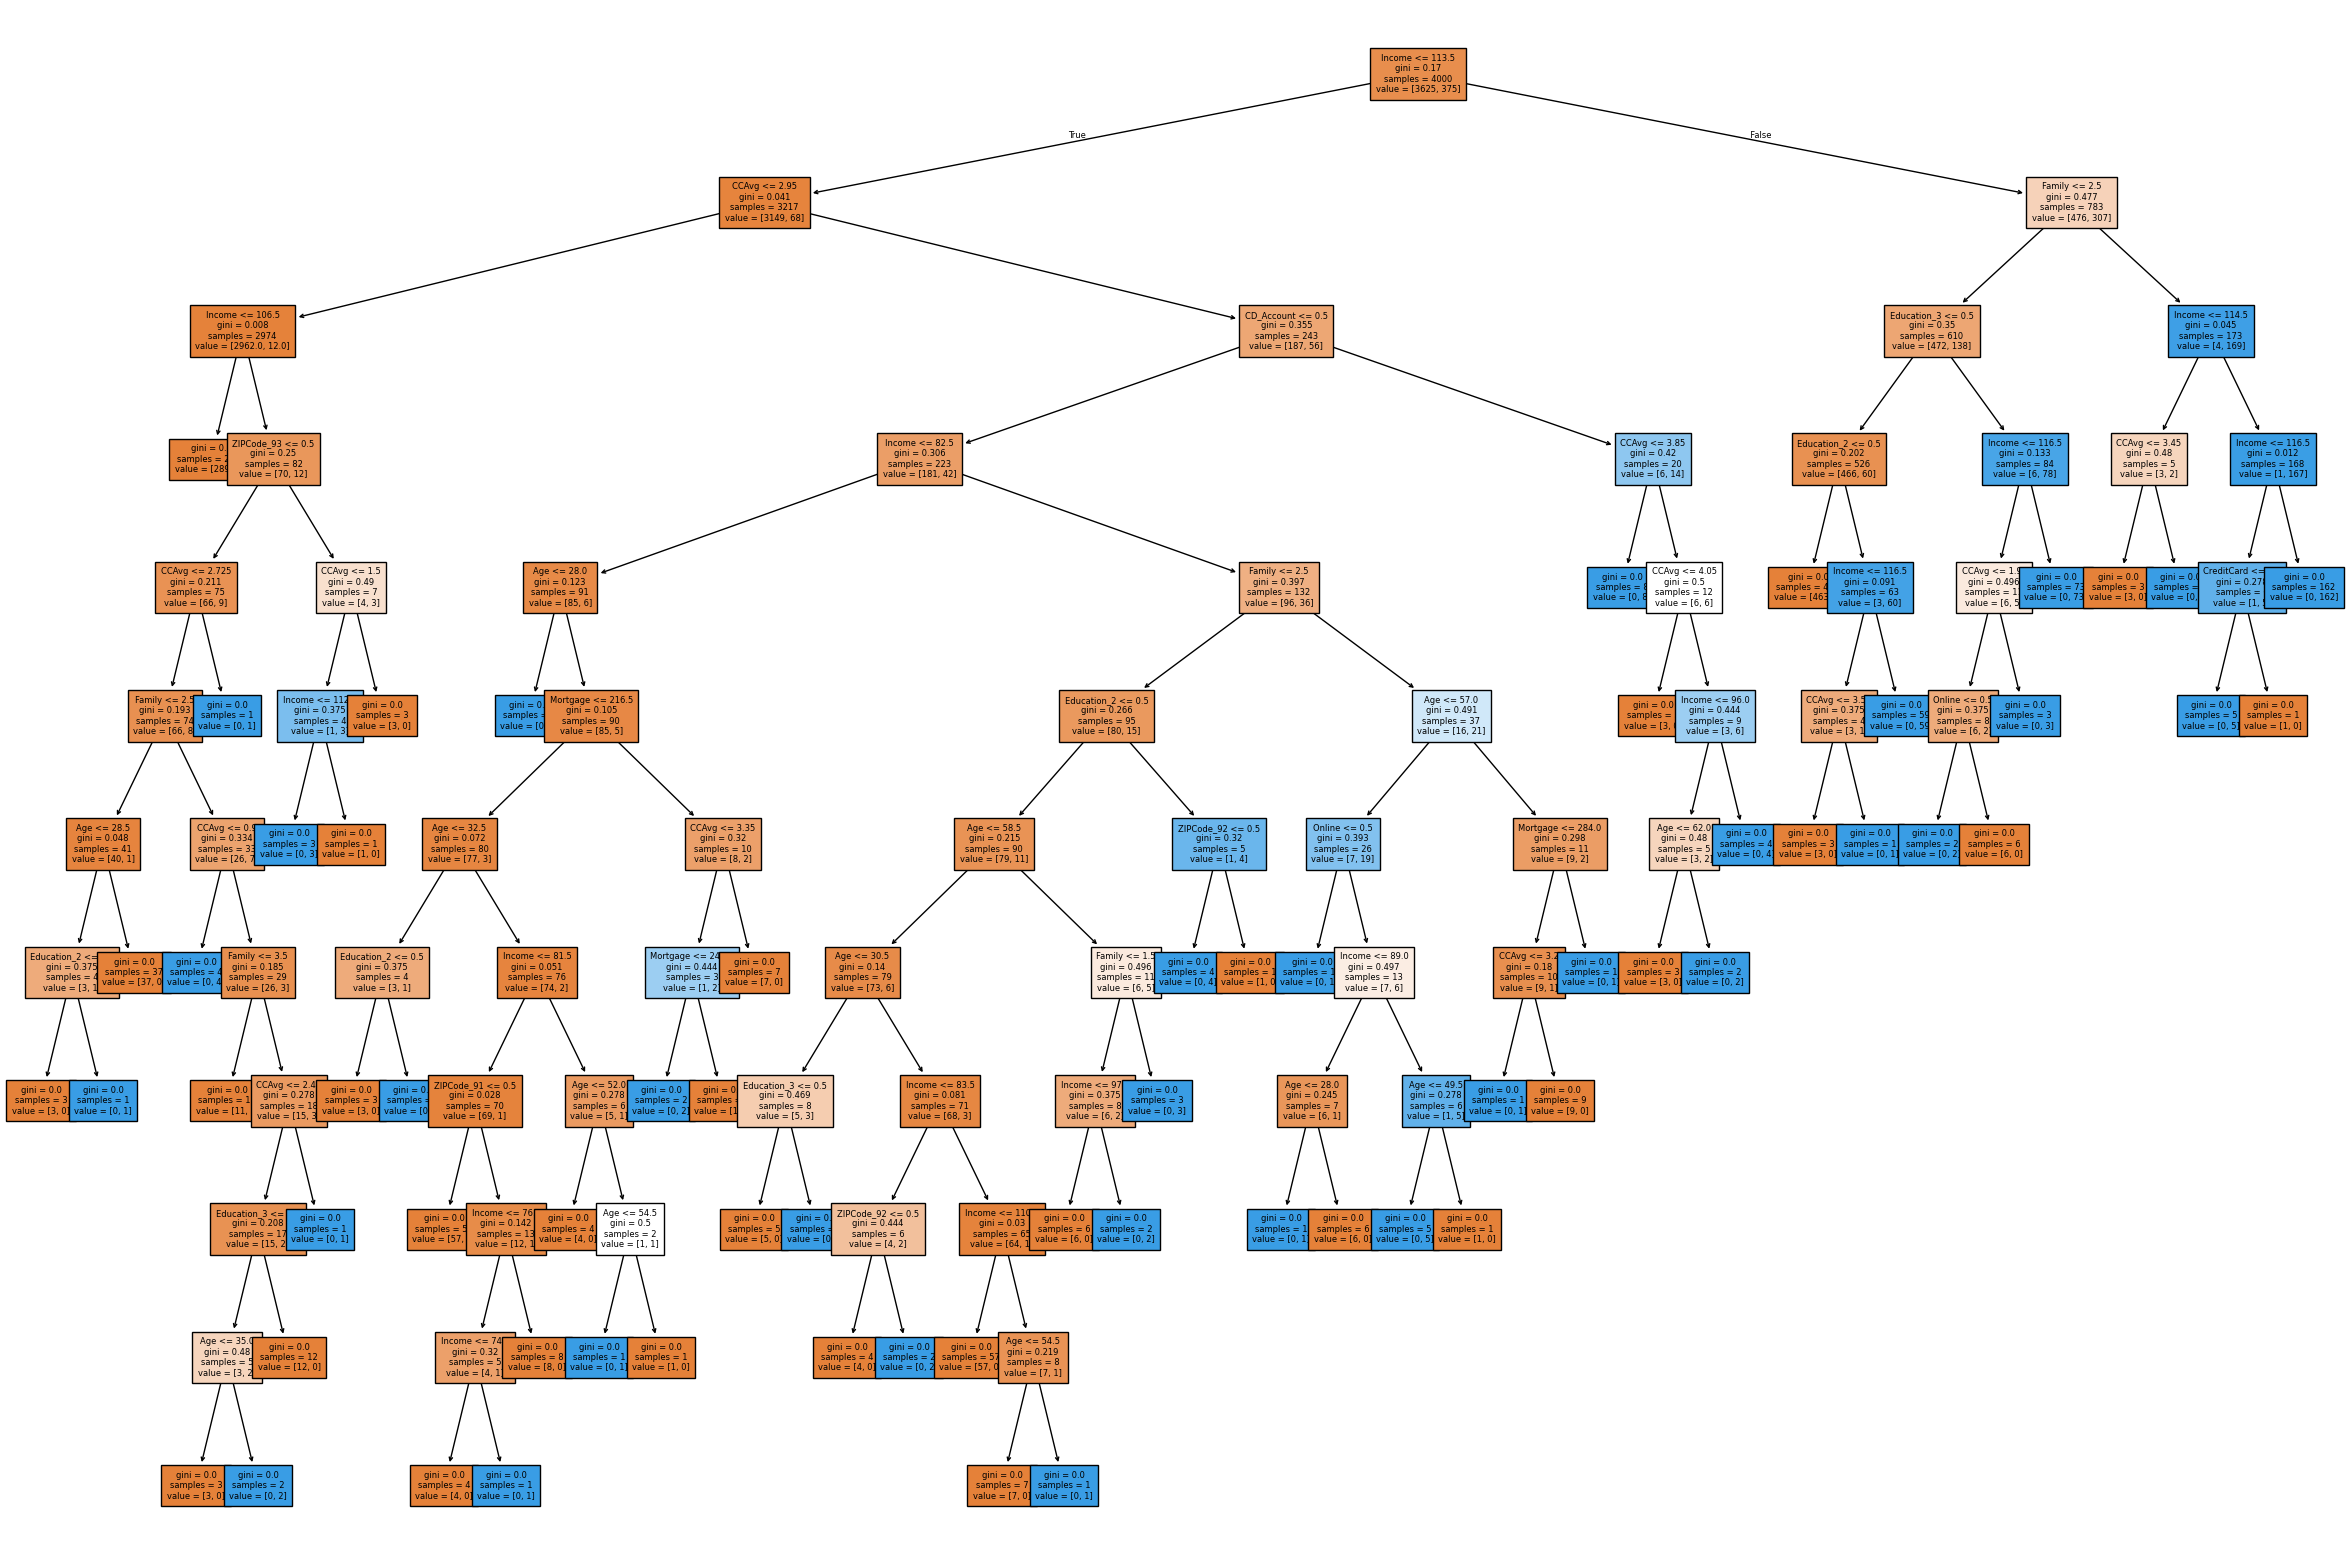

In [ ]:
plt.figure(figsize=(30, 20))
out = tree.plot_tree(
    model,
    feature_names=feature_names,
    filled=True,
    fontsize = 6,
    node_ids=False,
    class_names=None,
)
plt.show()

In [ ]:
print(tree.export_text(model, feature_names=feature_names, show_weights=True))

|--- Income <= 113.50
|   |--- CCAvg <= 2.95
|   |   |--- Income <= 106.50
|   |   |   |--- weights: [2892.00, 0.00] class: 0
|   |   |--- Income >  106.50
|   |   |   |--- ZIPCode_93 <= 0.50
|   |   |   |   |--- CCAvg <= 2.73
|   |   |   |   |   |--- Family <= 2.50
|   |   |   |   |   |   |--- Age <= 28.50
|   |   |   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |   |   |--- weights: [3.00, 0.00] class: 0
|   |   |   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |   |   |--- Age >  28.50
|   |   |   |   |   |   |   |--- weights: [37.00, 0.00] class: 0
|   |   |   |   |   |--- Family >  2.50
|   |   |   |   |   |   |--- CCAvg <= 0.90
|   |   |   |   |   |   |   |--- weights: [0.00, 4.00] class: 1
|   |   |   |   |   |   |--- CCAvg >  0.90
|   |   |   |   |   |   |   |--- Family <= 3.50
|   |   |   |   |   |   |   |   |--- weights: [11.00, 0.00] class: 0
|   |   |   |   |   |   |   |--- Fa

**OBSERVATIONS**:

---
- The decision tree starts with Income as the root node then randomly selects other parameters to expand further.
- The model decided to split at Income <= 113.5 at root,
  - then on the left (Income <= 113.5 True) considered CCAvg, Income again and so on
  - then on the right considered Family, Education, Income again and so on, as parameters to drill down
- The gini impurity as expected at leaf nodes is 0


In [ ]:
print( pd.DataFrame(
        model.feature_importances_, columns=["Imp"], index=X_train.columns
    ).sort_values(by="Imp", ascending=False)
)

                         Imp
Income              0.305415
Family              0.242681
Education_2         0.158822
Education_3         0.148576
CCAvg               0.070729
Age                 0.034151
CD_Account          0.014139
Online              0.009959
ZIPCode_92          0.006277
Mortgage            0.004819
CreditCard          0.002452
ZIPCode_93          0.001794
ZIPCode_91          0.000184
Securities_Account  0.000000
ZIPCode_94          0.000000
ZIPCode_96          0.000000
ZIPCode_95          0.000000


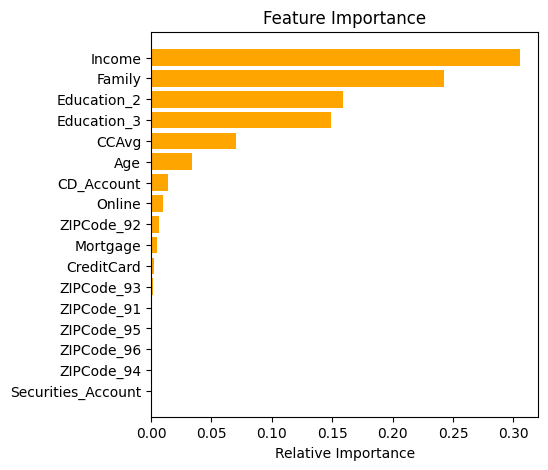

In [ ]:
importances = model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(5, 5))
plt.title("Feature Importance")
plt.barh(range(len(indices)), importances[indices], color="orange", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

**OBSERVATIONS**:
- Based on the Feature Importance,
  - Income, Family, Education, CCAvg have a significant importance (In order of importance) in determining the probability of Personal Loan
  - Mortgage, CreditCard, ZIPCode and Securities_Account hardly have any importance


### Base Model Evaluation (Testing data)

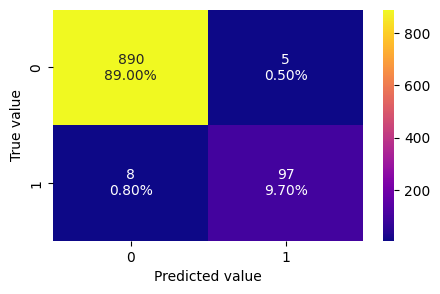

In [ ]:
compute_confusion_matrix(model, X_test, y_test)

**OBSERVATIONS**:

---
- True Meaning:  The customer will have/opt for a Personal Loan
- False Meaning: The customer will not have/ not opt for a Personal Loan
---
- True positive : Predicted True, Actual True: **9.7%**
- True negative : Predicted False, Actual False: **89.0%**
- False positive : Predicted True, Actual False: **0.5%**
- False negative : Predicted False, Actual True: **0.8%**

In [ ]:
decision_tree_perf_test = compute_model_evaluation_criterion(model, X_test, y_test)
decision_tree_perf_test

,Accuracy,Recall,Precision,F1
0,0.987,0.92381,0.95098,0.937198


**OBSERVATIONS**:

---

- Accuracy, Recall, Precision, F1 Score on training set was all 1.0 which is right since this was the first time we are building the model
- The same metrics on the test data is all > 0.9 which is pretty good.
---

- The Decision Tree with gini impurirties is quite big and complex. So we should perform pruning of the tree


## Model Performance Improvement

In [ ]:
# Redefining the training set is not a necessary step but dropping additional columns which have almost no feature importance based on prev. analysis
X = data.drop(["Personal_Loan", "Experience","ZIPCode","Securities_Account","Mortgage", "CreditCard"], axis=1)
Y = data["Personal_Loan"]

X = pd.get_dummies(X, columns=["Education"], drop_first=True)

X = X.astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42)

#update feature names for future analysis
feature_names = list(X_train.columns)

X.head()

,Age,Income,Family,CCAvg,CD_Account,Online,Education_2,Education_3
0,25.0,49.0,4.0,1.6,0.0,0.0,0.0,0.0
1,45.0,34.0,3.0,1.5,0.0,0.0,0.0,0.0
2,39.0,11.0,1.0,1.0,0.0,0.0,0.0,0.0
3,35.0,100.0,1.0,2.7,0.0,0.0,1.0,0.0
4,35.0,45.0,4.0,1.0,0.0,0.0,1.0,0.0


### Pre pruning
TRAINING DATA

In [ ]:
# tree params:
max_depth_values = np.arange(2, 11, 2)
max_leaf_nodes_values = np.arange(10, 49, 10)
min_samples_split_values = np.arange(10, 49, 10)

# best model, perf vars
best_estimator = None
best_score_diff = float('inf')

for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                random_state=42
            )

            estimator.fit(X_train, y_train)

            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            train_f1_score = f1_score(y_train, y_train_pred)
            test_f1_score = f1_score(y_test, y_test_pred)

            # calculate diff between training and test f1 score
            score_diff = abs(train_f1_score - test_f1_score)

            # update model (best_estimator) and score_diff if the current score diff < best score diff
            if score_diff < best_score_diff:
                best_score_diff = score_diff
                best_estimator = estimator

# Print the best parameters
print("Best parameters found:")
print(f"Max depth: {best_estimator.max_depth}")
print(f"Max leaf nodes: {best_estimator.max_leaf_nodes}")
print(f"Min samples split: {best_estimator.min_samples_split}")
print(f"Best score diff: {best_score_diff}")

Best parameters found:
Max depth: 8
Max leaf nodes: 30
Min samples split: 20
Best score diff: 0.0004964539007091817


**OBSERVATIONS**:

---
- Tried a few changes to tree params to check best score diff, but not a lot of difference. So retaining the values as above.


In [ ]:
# create decision tree after prepruning on best model params
dtree2 = best_estimator
dtree2.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=np.int64(8), max_leaf_nodes=np.int64(30),
                       min_samples_split=np.int64(20), random_state=42)

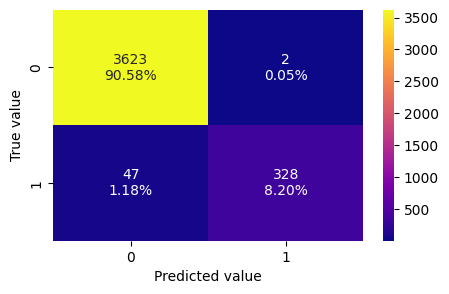

In [ ]:
compute_confusion_matrix(dtree2, X_train, y_train)

**OBSERVATIONS**:

---
- True Meaning:  The customer will have/opt for a Personal Loan
- False Meaning: The customer will not have/ not opt for a Personal Loan
---
- True positive : Predicted True, Actual True: **8.2%**
- True negative : Predicted False, Actual False: **90.58%**
- False positive : Predicted True, Actual False: **0.05%**
- False negative : Predicted False, Actual True: **1.18%**

In [ ]:
decision_tree_preprun_perf_train = compute_model_evaluation_criterion(dtree2, X_train, y_train)
decision_tree_preprun_perf_train

,Accuracy,Recall,Precision,F1
0,0.98775,0.874667,0.993939,0.930496


#### Visualization of Decision Tree

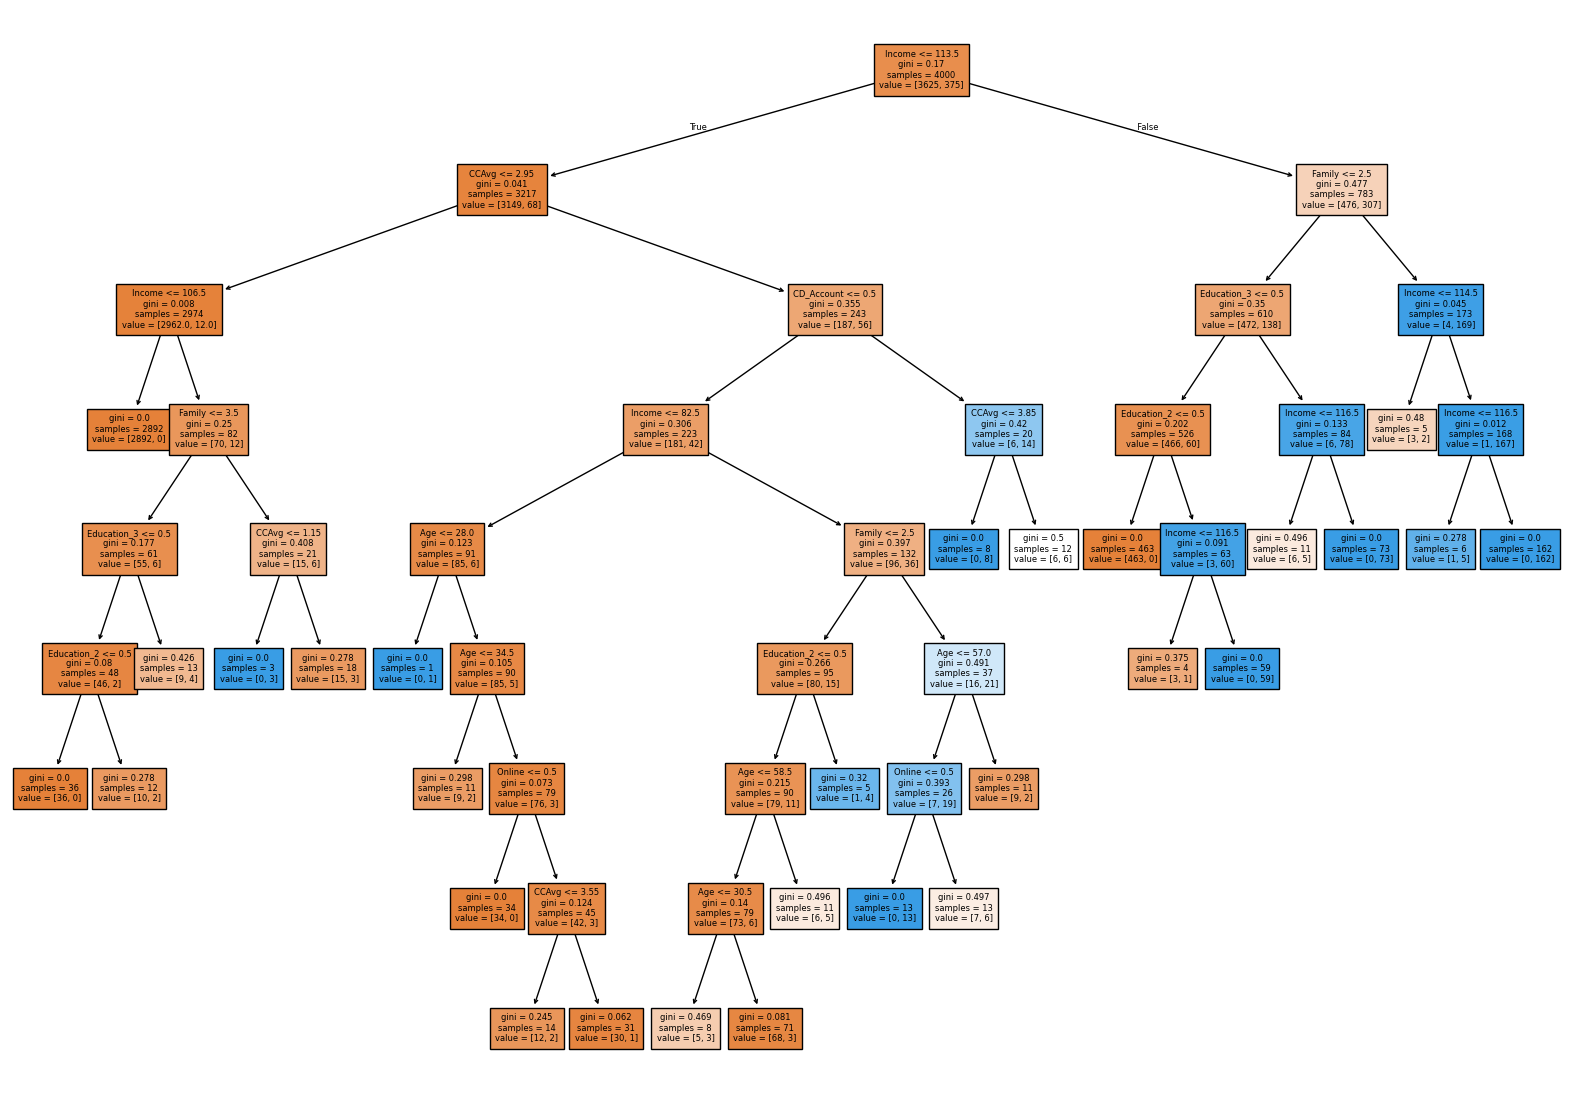

In [ ]:
plt.figure(figsize=(20, 14))
out = tree.plot_tree(
    dtree2,
    feature_names=feature_names,
    filled=True,
    fontsize=6,
    node_ids=False,
    class_names=None,
)
plt.show()

In [ ]:
print(tree.export_text(estimator, feature_names=feature_names, show_weights=True))

|--- Income <= 113.50
|   |--- CCAvg <= 2.95
|   |   |--- Income <= 106.50
|   |   |   |--- weights: [2892.00, 0.00] class: 0
|   |   |--- Income >  106.50
|   |   |   |--- Family <= 3.50
|   |   |   |   |--- Education_3 <= 0.50
|   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |--- weights: [36.00, 0.00] class: 0
|   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |--- weights: [10.00, 2.00] class: 0
|   |   |   |   |--- Education_3 >  0.50
|   |   |   |   |   |--- weights: [9.00, 4.00] class: 0
|   |   |   |--- Family >  3.50
|   |   |   |   |--- weights: [15.00, 6.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- Income <= 82.50
|   |   |   |   |--- Age <= 28.00
|   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |--- Age >  28.00
|   |   |   |   |   |--- Age <= 34.50
|   |   |   |   |   |   |--- weights: [9.00, 2.00] class: 0
|   |   |   |   |   |--- Age >  34.50
|   |   |   |   |   |   |--- 

**OBSERVATIONS**:

---
- The tree after prepruning is created based on the parameters determined by prepruning (by taking best score diff)
- So the new tree is built with depth of 8, 27 splits, 28 leaf nodes.
- The splits are similar to the base model ones. But now we have eliminated a few columns on X before starting based on the feature importance / Gini importance from previous analysis.
- The gini impurity at leaf nodes is not always 0 but the model is more optimized for performance without affecting the accuracy, precision, recall and f1 scores much.


In [ ]:
print( pd.DataFrame(
        estimator.feature_importances_, columns=["Imp"], index=X_train.columns
    ).sort_values(by="Imp", ascending=False)
)

                  Imp
Income       0.326735
Family       0.269508
Education_2  0.175514
Education_3  0.162373
CCAvg        0.038729
CD_Account   0.015995
Age          0.010859
Online       0.000287


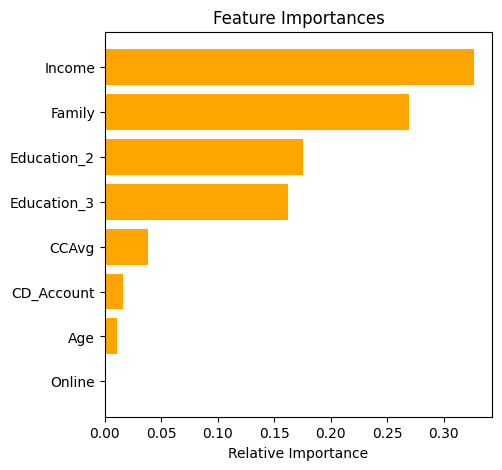

In [ ]:
importances = estimator.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(5, 5))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="orange", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

**OBSERVATIONS**:

---
- The features considered currently all have a certain significance, except for *Online*
- Income, Family, Education have the highest Feature importance


### Pre pruning
TESTING DATA

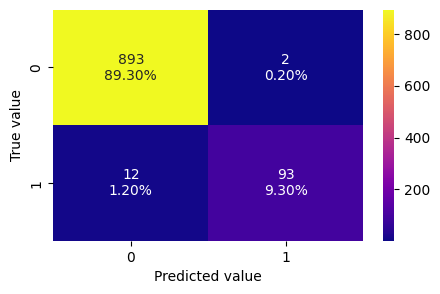

In [ ]:
compute_confusion_matrix(dtree2, X_test, y_test)

**OBSERVATIONS**:

---
- True Meaning:  The customer will have/opt for a Personal Loan
- False Meaning: The customer will not have/ not opt for a Personal Loan
---
- True positive : Predicted True, Actual True: **9.3%**
- True negative : Predicted False, Actual False: **89.3%**
- False positive : Predicted True, Actual False: **0.2%**
- False negative : Predicted False, Actual True: **1.2%**

In [ ]:
decision_tree_preprun_perf_test = compute_model_evaluation_criterion(dtree2, X_test, y_test)
decision_tree_preprun_perf_test

,Accuracy,Recall,Precision,F1
0,0.986,0.885714,0.978947,0.93


**OBSERVATIONS**:

---
- Accuracy, Recall, Precision, F1 score after Prepruning and fitting the model on training set is pretty similar to the one before prepruning on the test data. This indicates a good model
- Recall on test data is slightly higher than training set, and vice versa for precision, but f1 score is fairly similar


### Post pruning
TRAINING DATA

For Post pruning, we will do it based on Cost Complexity pruning method of calculating ccp alpha where the impurity of the node is not effectively high. Following are the calculations and plotting of the graphs to do the same

In [ ]:
clf = DecisionTreeClassifier(random_state=42)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = abs(path.ccp_alphas), path.impurities

pd.DataFrame(path)

,ccp_alphas,impurities
0,0.000000,0.000000
1,0.000161,0.000484
2,0.000200,0.000884
3,0.000225,0.001334
4,0.000240,0.002293
5,0.000246,0.002785
6,0.000249,0.003282
7,0.000267,0.003549
8,0.000319,0.004507
9,0.000368,0.004876


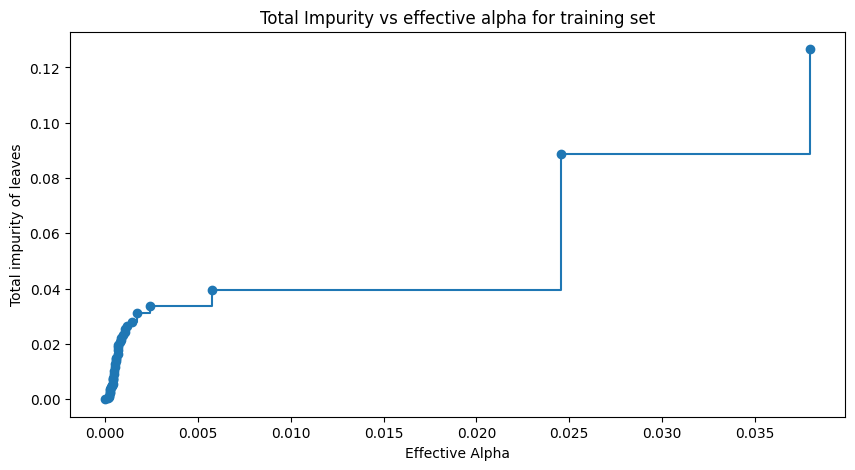

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("Effective Alpha")
ax.set_ylabel("Total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

In [ ]:
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)

print("Number of nodes in the last tree: {} with ccp_alpha: {}".format(clfs[-1].tree_.node_count, ccp_alphas[-1]))

Number of nodes in the last tree: 1 with ccp_alpha: 0.04332510361744618


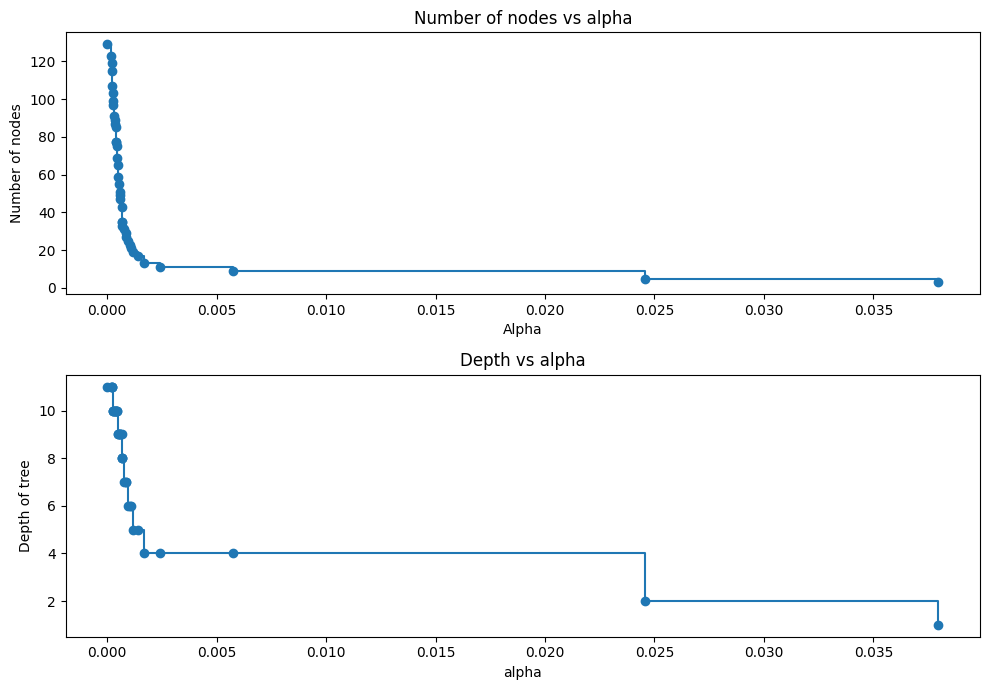

In [ ]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("Alpha")
ax[0].set_ylabel("Number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("Depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

In [ ]:
#Based on previous calculations of recall, precision and f1_score, f1_score is more stable and effective, so will calculate that for the training and test data to check it against alpha value
f1_score_train = []
for clf in clfs:
    pred_train = clf.predict(X_train)
    values_train = f1_score(y_train, pred_train)
    f1_score_train.append(values_train)

f1_score_test = []
for clf in clfs:
    pred_test = clf.predict(X_test)
    values_test = f1_score(y_test, pred_test)
    f1_score_test.append(values_test)

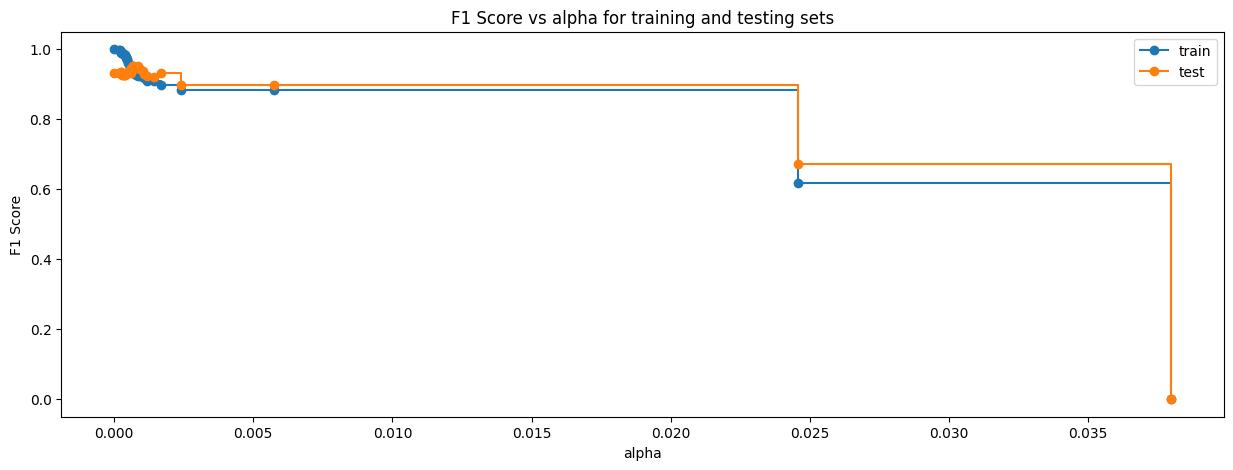

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlabel("alpha")
ax.set_ylabel("F1 Score")
ax.set_title("F1 Score vs alpha for training and testing sets")
ax.plot(ccp_alphas, f1_score_train, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, f1_score_test, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

**OBSERVATIONS**:

---
Based on the above plots, the effective alpha value without significant increase in impurity, or decrease in f1_score is the point between 0.005-0.01


In [ ]:
index_best_model = np.argmax(f1_score_test)
best_model = clfs[index_best_model]
print(best_model)

DecisionTreeClassifier(ccp_alpha=np.float64(0.0008567334159097198),
                       random_state=42)


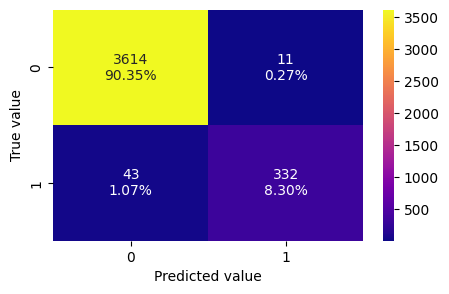

In [ ]:
compute_confusion_matrix(best_model, X_train, y_train)

**OBSERVATIONS**:

---
- True Meaning:  The customer will have/opt for a Personal Loan
- False Meaning: The customer will not have/ not opt for a Personal Loan
---
- True positive : Predicted True, Actual True: **8.3%**
- True negative : Predicted False, Actual False: **90.35%**
- False positive : Predicted True, Actual False: **0.27%**
- False negative : Predicted False, Actual True: **1.07%**

In [ ]:
decision_tree_postprun_perf_train = compute_model_evaluation_criterion(best_model, X_train, y_train)
decision_tree_postprun_perf_train

,Accuracy,Recall,Precision,F1
0,0.9865,0.885333,0.96793,0.924791


### Visualization of Decision Tree

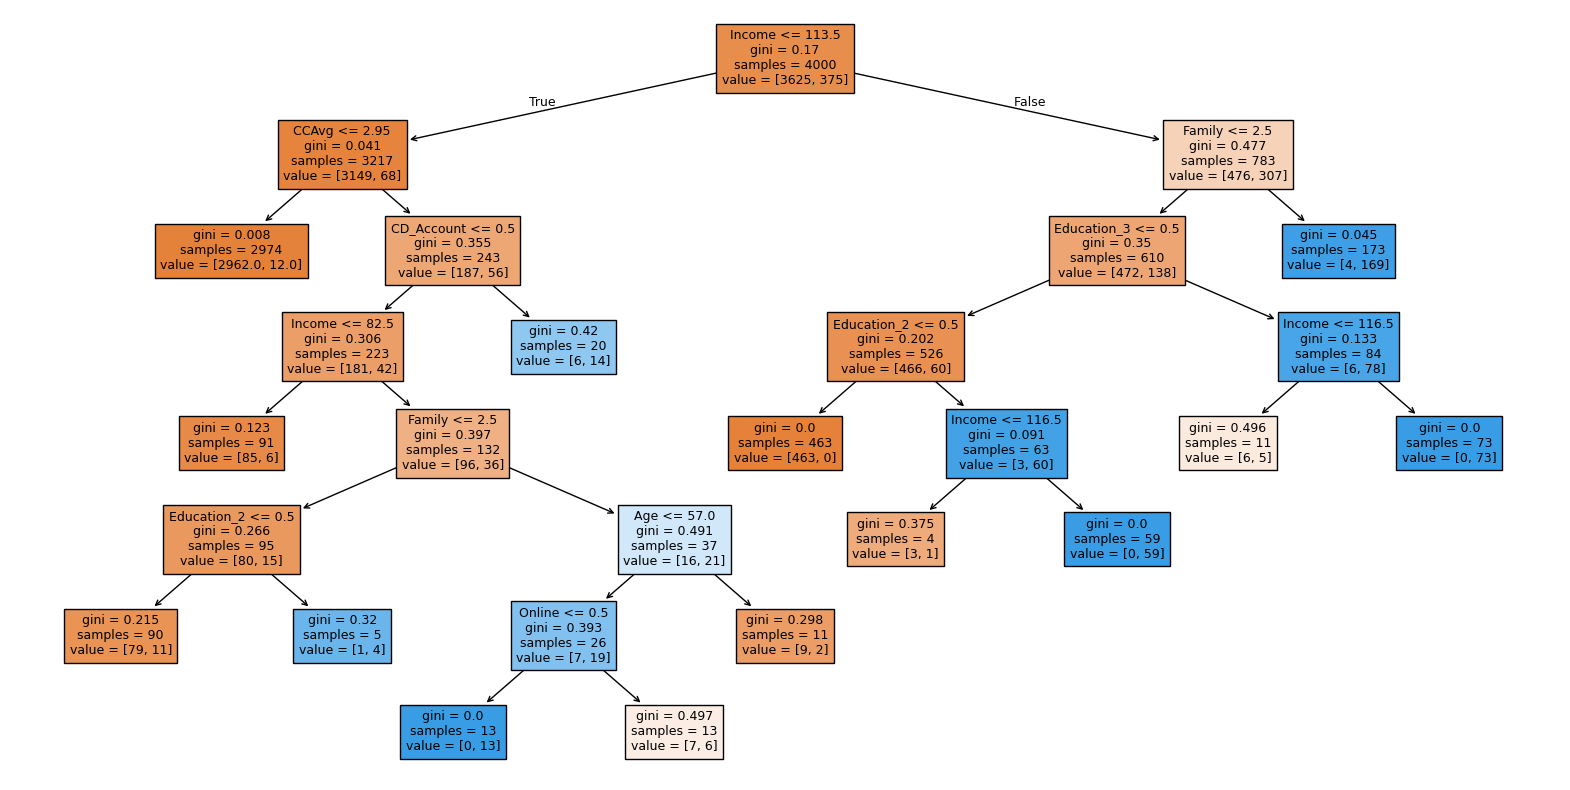

In [ ]:
plt.figure(figsize=(20, 10))
out = tree.plot_tree(
    best_model,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
plt.show()

**OBSERVATIONS**:

---
- The tree after post pruning is created based on the parameters determined by postpruning (ccp alpha)
- So the new tree is even smaller and computationally more effective.
- The splits are similar to the base and prepruning model splits.
- The accuracy, precision, recall and f1 scores have remained very similar so prepruning which is also a good sign.

---

- The value shows the count of No Personal Loan, Personal Loan customers in the array at indices 0 and 1 respectively.
- So For eg, Income >113.5 and Family >2.5 have 4 customers with No Personal Loan and 163 customers with Personal Loan. This is a good target set. gini impurity in this section is 0.045.

In [ ]:
print(tree.export_text(best_model, feature_names=feature_names, show_weights=True))

|--- Income <= 113.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [2962.00, 12.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- Income <= 82.50
|   |   |   |   |--- weights: [85.00, 6.00] class: 0
|   |   |   |--- Income >  82.50
|   |   |   |   |--- Family <= 2.50
|   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |--- weights: [79.00, 11.00] class: 0
|   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |--- weights: [1.00, 4.00] class: 1
|   |   |   |   |--- Family >  2.50
|   |   |   |   |   |--- Age <= 57.00
|   |   |   |   |   |   |--- Online <= 0.50
|   |   |   |   |   |   |   |--- weights: [0.00, 13.00] class: 1
|   |   |   |   |   |   |--- Online >  0.50
|   |   |   |   |   |   |   |--- weights: [7.00, 6.00] class: 0
|   |   |   |   |   |--- Age >  57.00
|   |   |   |   |   |   |--- weights: [9.00, 2.00] class: 0
|   |   |--- CD_Account >  0.50
|   |   |   |--- weights: [6.00, 14.00] class: 1
|--- Income >  

In [ ]:
print(
    pd.DataFrame(
        best_model.feature_importances_, columns=["Imp"], index=X_train.columns
    ).sort_values(by="Imp", ascending=False)
)

                  Imp
Income       0.317912
Family       0.272233
Education_2  0.177652
Education_3  0.162682
CCAvg        0.038988
CD_Account   0.016267
Age          0.007886
Online       0.006380


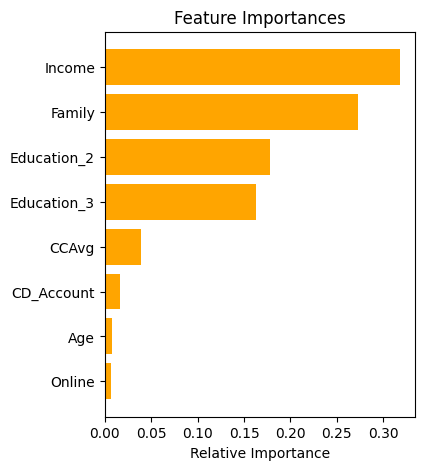

In [ ]:
importances = best_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(4, 5))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="orange", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

### Post pruning
TESTING DATA

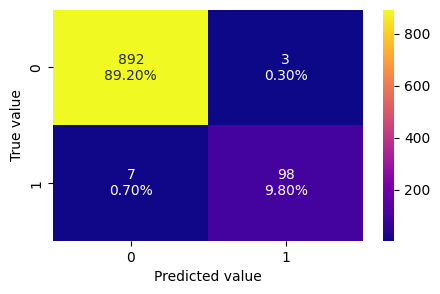

In [ ]:
compute_confusion_matrix(best_model, X_test, y_test)

**OBSERVATIONS**:

---
- True Meaning:  The customer will have/opt for a Personal Loan
- False Meaning: The customer will not have/ not opt for a Personal Loan
---
- True positive : Predicted True, Actual True: **9.8%**
- True negative : Predicted False, Actual False: **89.2%**
- False positive : Predicted True, Actual False: **0.3%**
- False negative : Predicted False, Actual True: **0.7%**

In [ ]:
decision_tree_postprun_perf_test = compute_model_evaluation_criterion(best_model, X_test, y_test)
decision_tree_postprun_perf_test

,Accuracy,Recall,Precision,F1
0,0.99,0.933333,0.970297,0.951456


**OBSERVATIONS**:

---

- The accuracy, precision, recall and f1 scores have improved on the training set are very good numbers!! So this is an ideal model amongst all.
- The feature importance has remained similar on post pruning and we have effectively considered all the important features.

## Model Performance Comparison and Final Model Selection

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [decision_tree_perf_train.T, decision_tree_preprun_perf_train.T, decision_tree_postprun_perf_train.T], axis=1,
)
models_train_comp_df.columns = ["Base", "Pre-Pruning", "Post-Pruning"]
print("Training performance comparison:")
print(models_train_comp_df)
print("\n ------------ \n")

# testing performance comparison

models_test_comp_df = pd.concat(
    [decision_tree_perf_test.T, decision_tree_preprun_perf_test.T, decision_tree_postprun_perf_test.T], axis=1,
)
models_test_comp_df.columns = ["Base", "Pre-Pruning", "Post-Pruning"]
print("Test set performance comparison:")
print(models_test_comp_df)

Training performance comparison:
           Base  Pre-Pruning  Post-Pruning
Accuracy    1.0     0.987750      0.986500
Recall      1.0     0.874667      0.885333
Precision   1.0     0.993939      0.967930
F1          1.0     0.930496      0.924791

 ------------ 

Test set performance comparison:
               Base  Pre-Pruning  Post-Pruning
Accuracy   0.987000     0.986000      0.990000
Recall     0.923810     0.885714      0.933333
Precision  0.950980     0.978947      0.970297
F1         0.937198     0.930000      0.951456


**OBSERVATIONS**:

---

- Final model selection is the Post Pruned model which has the best statistics on training and test data as illustrated above
- Stats on test data of post pruned model: Accuracy: 0.99, F1 score: 0.95

## Actionable Insights and Business Recommendations


What recommedations would you suggest to the bank?


---



Based on the evaluation,
- Income is a high influencing factor for targeting data. Family and Education are close second. The bank should target these customers for marketing to opt for Personal Loan
- So for eg, based on the decision Tree plot, the bank should look at targeting customers with Income > 113.5 and Family size > 2.5
- Other Factors like Education, CC_Avg, CD_Account, Age, Online can also be considered. Other factors in the data have negligible importance in determining if a customer opts for Personal Loan.
- Age (between 26 and 65 inclusive) can also be a factor based on the Bivariant plot too for target customers. Possibly this is the working population with income enough to afford a Personal Loan and the need for one.

From Confusion matrix,
- We should look at targeting the customers under False negatives in the confusion matrix, because that is a potential we are missing.
- If the marketing cost is not high, we should not bother about the small values in targeting False positives.
- Our ideal customer target is to True negative population which we want to convert to True Positive

From model calculations,
- Our model with prepruning and post pruning done using the effective parameters has resulted in great performance on training and testing data.
- The bank can use the final model to predict for a non-test set customer's probability to opt for a Personal Loan based on his Income, Education, etc.


___